# Kimi K3 from Scratch in NumPy — Kimi Delta Attention, Attention Residuals, Stable LatentMoE, step by step

This notebook implements the architecture of **Kimi K3** (Moonshot AI, technical report arXiv:2607.24653) in pure NumPy, with every intermediate matrix printed and every formula written out — the same treatment the companion notebook gave to the original Transformer.

Kimi K3 is a **2.8-trillion-parameter** Mixture-of-Experts model with 104B activated parameters, native vision, and a **1-million-token** context window. Everything below runs at $d_{model} = 8$ with 8 tokens, so you can check the arithmetic by hand. The structure is identical; only the numbers shrink.

---

## What is different from the original Transformer

If you have the Vaswani notebook in mind, here is the whole delta. Each row is a section below.

| # | Transformer (2017) | Kimi K3 (2026) | Why |
|---|---|---|---|
| 1 | Sinusoidal positional encoding added to the input | **No positional encoding at all** (NoPE) | position is carried implicitly by the decay/gating of the recurrent layers |
| 2 | Every layer is softmax attention, $O(n^2)$, KV cache grows with $n$ | **3 Kimi Delta Attention layers : 1 Gated MLA layer** | KDA keeps a *fixed-size* state $S \in \mathbb{R}^{d_k \times d_v}$; only 1 layer in 4 pays the quadratic cost |
| 3 | LayerNorm (mean-centred) | **RMSNorm** (no mean subtraction) | cheaper, and empirically no worse |
| 4 | Post-LN: `LN(x + Sublayer(x))` | **Pre-norm**: `x + Sublayer(RMSNorm(x))` | stable at 93 layers |
| 5 | Residual stream: $h_l = h_{l-1} + f(h_{l-1})$ | **Attention Residuals**: each sublayer *attends over depth* to choose its own input | a single running sum is "a bottleneck reminiscent of RNNs over time" |
| 6 | Dense FFN with ReLU | **Stable LatentMoE**: 896 experts, 16 active, in a latent space of width $d/2$, with SiTU-GLU | width scaling without width cost |
| 7 | — | **Quantile Balancing** for expert load | exact dual coordinate minimiser, no learning rate to tune |
| 8 | Encoder + decoder | Decoder-only | as in every modern LLM |

---

## The chain carried end to end

**tokens → IDs → embeddings → [ AttnRes read → RMSNorm → KDA/MLA → group sum ] ×8 → block summaries → Final Block AttnRes → RMSNorm → linear → logits → softmax → next token**

and then the same thing again **one token at a time**, to show that the KDA recurrent state makes incremental decoding exact and $O(1)$ in sequence length.

---

## Honest caveat, stated once

The weights here are **random, not trained**. Every number is computed correctly and every identity is verified, but the predicted token is meaningless. The purpose is the mechanics of the forward pass.

Two things are deliberately left out: the vision tower (MoonViT-V2) and the MXFP4 quantisation-aware training. Both are described in the report; neither changes the shapes below.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=3, suppress=True, linewidth=160)

print("NumPy:", np.__version__)

NumPy: 2.4.4


---
# 0. Display helpers

Identical in spirit to the Transformer notebook: every matrix product prints **both operands**, the result, one element worked out term by term, and the shape rule. Two extra helpers are added for things the Transformer did not have — the $d_k \times d_v$ recurrent state, and vectors.

In [2]:
# ============================================================================
#  DISPLAY HELPERS
# ============================================================================

def expand(u, v, per_line=4):
    """Write out a dot product term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out: lines.append(out)
    return "\n      ".join(lines)


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                max_cols=12, rows_A=None, note=None):
    """Print both operands of A @ B = C, then verify one element by hand."""
    print("=" * 78)
    print(f"  {na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note: print(f"  {note}")
    print("=" * 78)

    def show(M, name, labels=None, cap=max_cols):
        cut = M.shape[1] > cap
        Ms = M[:, :cap] if cut else M
        print(f"\n{name} =" + (f"   [showing first {cap} of {M.shape[1]} columns]" if cut else ""))
        for r in range(Ms.shape[0]):
            lab = f"{labels[r]:>10} | " if labels is not None else ""
            print("   " + lab + "  ".join(f"{v:+8.3f}" for v in Ms[r]))

    show(A, na, rows_A); show(B, nb); show(C, nc, rows_A)

    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row  {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col  {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    val = float(A[i] @ B[:, j])
    print(f"      = {val:+.6f}   |  from array: {C[i, j]:+.6f}   |  "
          f"MATCH: {np.isclose(val, C[i, j])}")


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    """Print an element-wise operation with both operands."""
    print("=" * 78)
    print(f"  {nc} = {na} {op} {nb}      all three are {A.shape} - element-wise, no mixing")
    print("=" * 78)
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10} | " if rows is not None else f"{r:>10} | "
        print(f"\n{lab}")
        print("   " + f"{na:>16}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>16}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>16}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    ok = A[0, 0] + B[0, 0] if op == "+" else (A[0, 0] * B[0, 0] if op == "*" else A[0, 0] - B[0, 0])
    print(f"\n  check element [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(ok, C[0,0])}")


def show_mat(M, name, rows=None, cols=None, prec=4):
    """Print a single matrix with optional row/column labels."""
    M = np.atleast_2d(M)
    head = "          " + "  ".join(f"{c:>9}" for c in (cols if cols is not None
                                   else [f"c{j}" for j in range(M.shape[1])]))
    print(f"{name}  {M.shape}")
    print(head)
    for r in range(M.shape[0]):
        lab = f"{rows[r]:>9} " if rows is not None else f"{r:>9} "
        print(lab + "  ".join(f"{v:+9.{prec}f}" for v in M[r]))


def show_state(S, title="S", kl=None, vl=None):
    """Print the KDA recurrent state, rows = key channels, cols = value channels."""
    kl = kl or [f"k{i}" for i in range(S.shape[0])]
    vl = vl or [f"v{j}" for j in range(S.shape[1])]
    show_mat(S, title, rows=kl, cols=vl)


def check(name, a, b, tol=1e-9):
    """Assert-and-report an identity."""
    d = float(np.max(np.abs(np.asarray(a) - np.asarray(b))))
    print(f"  {name:<58} max|diff| = {d:.3e}   MATCH: {d < tol}")
    return d


print("Display helpers ready: expand, show_matmul, show_elementwise, show_mat, show_state, check.")

Display helpers ready: expand, show_matmul, show_elementwise, show_mat, show_state, check.


---
# 1. The task and the hyper-parameters

One sentence, 8 tokens, decoder-only. There is no encoder and no source/target split — Kimi K3 is a causal language model, so the task is simply: given tokens $1 \dots t$, predict token $t+1$.

The dimensions are chosen so that **every structural ratio of the real model survives**:

| | this notebook | Kimi K3 | preserved? |
|---|---|---|---|
| $d_{model}$ | 8 | 7,168 | — |
| tokens $T$ | 8 | 1,000,000 | — |
| layers | 8 = 2 blocks × 4 | 93 | — |
| KDA : MLA per block | **3 : 1** | **3 : 1** | ✅ |
| chunk size $C$ | 4 | 64–128 | — |
| $g_{\min}$ | **−5** | **−5** | ✅ |
| MoE latent $\ell$ | 4 = $d/2$ | 3,584 = $d/2$ | ✅ |
| routed experts $n$ | 8 | 896 | — |
| active $k$ | 2 | 16 | — |
| sparsity $n/k$ | 4 | 56 | — |
| shared experts | 1 | 2 | — |
| SiTU-GLU $\beta_1, \beta_2$ | **4, 25** | **4, 25** | ✅ |
| layer 1 FFN | **dense** | **dense** | ✅ |
| AttnRes | 2 blocks | 8 blocks (7×12 + 1×9 layers) | — |

The target load per expert works out to $q = mk/n = 8 \cdot 2 / 8 = 2$ tokens, which makes the Quantile Balancing section in §9 exactly checkable by counting.

In [3]:
D_MODEL    = 8              # d_model
VOCAB_SIZE = 500

# --- Kimi Delta Attention (the linear / recurrent layers) ---
KDA_HEADS = 2
D_K       = 4              # key dim per head
D_V       = 4              # value dim per head
CHUNK     = 4              # chunkwise parallel form
G_MIN     = -5.0           # lower bound on the log-decay

# --- Gated MLA (the one global layer per block) ---
MLA_HEADS = 2
D_H       = 4              # per-head dim
D_C       = 4              # latent KV dim -- this is what gets cached

# --- Stable LatentMoE ---
ELL       = D_MODEL // 2   # 4  -- routed experts work in this latent space
N_ROUTED  = 8
K_TOP     = 2
N_SHARED  = 1
D_FF_EXP  = 8              # expert hidden width (inside the latent space)
D_FF_DENSE = 4 * D_MODEL   # 32 -- layer 1 is dense
BETA1, BETA2 = 4.0, 25.0   # SiTU-GLU soft caps

# --- depth ---
N_BLOCKS       = 2
LAYERS_PER_BLK = 4         # KDA, KDA, KDA, MLA
N_LAYERS       = N_BLOCKS * LAYERS_PER_BLK

sentence = "the cat sat on the mat and slept"
tokens   = sentence.split()
T        = len(tokens)

print(f"sentence : {sentence!r}")
print(f"tokens   : {tokens}")
print(f"T = {T}, d_model = {D_MODEL}, chunks of {CHUNK} -> {T // CHUNK} chunks")
print(f"layers   : {N_LAYERS} = {N_BLOCKS} blocks x {LAYERS_PER_BLK} "
      f"({LAYERS_PER_BLK-1} KDA + 1 MLA)")
print(f"sublayers: {2 * N_LAYERS}  (each layer = attention sublayer + FFN/MoE sublayer)")
print(f"MoE      : {N_ROUTED} routed experts, top-{K_TOP} -> sparsity {N_ROUTED//K_TOP},"
      f" latent width {ELL}")
print(f"target load per expert q = T*k/n = {T}*{K_TOP}/{N_ROUTED} = {T*K_TOP//N_ROUTED}")

sentence : 'the cat sat on the mat and slept'
tokens   : ['the', 'cat', 'sat', 'on', 'the', 'mat', 'and', 'slept']
T = 8, d_model = 8, chunks of 4 -> 2 chunks
layers   : 8 = 2 blocks x 4 (3 KDA + 1 MLA)
sublayers: 16  (each layer = attention sublayer + FFN/MoE sublayer)
MoE      : 8 routed experts, top-2 -> sparsity 4, latent width 4
target load per expert q = T*k/n = 8*2/8 = 2


---
# 2. Vocabulary and token IDs

Same convention as the Transformer notebook: IDs are random integers in $[50, 500)$, mimicking a real tokenizer where the ID is an arbitrary index carrying no meaning by itself. Three IDs are reserved below 50.

Note that `"the"` appears twice, at positions 0 and 4. In the Transformer notebook this was the motivating example for positional encoding: without PE, the two copies had *identical* input vectors. **Kimi K3 adds no positional encoding**, so here the two copies genuinely do start identical — and §6 shows where they stop being identical.

In [4]:
PAD_ID, SOS_ID, EOS_ID = 0, 1, 2

unique_words = []
for w in tokens:
    if w not in unique_words:
        unique_words.append(w)

rng_ids = np.random.default_rng(0)
chosen  = rng_ids.choice(np.arange(50, VOCAB_SIZE), size=len(unique_words), replace=False)
word2id = {w: int(i) for w, i in zip(unique_words, chosen)}
id2word = {i: w for w, i in word2id.items()}
id2word.update({PAD_ID: "<pad>", SOS_ID: "<sos>", EOS_ID: "<eos>"})

ids = np.array([word2id[w] for w in tokens])

print("vocabulary")
for w in unique_words:
    print(f"   {w:<8} -> {word2id[w]}")
print()
for p, (w, i) in enumerate(zip(tokens, ids)):
    dup = "   <- same ID as position 0" if p == 4 else ""
    print(f"  position {p}: {w:<8} id={i}{dup}")

vocabulary
   the      -> 83
   cat      -> 68
   sat      -> 170
   on       -> 277
   mat      -> 187
   and      -> 333
   slept    -> 427

  position 0: the      id=83
  position 1: cat      id=68
  position 2: sat      id=170
  position 3: on       id=277
  position 4: the      id=83   <- same ID as position 0
  position 5: mat      id=187
  position 6: and      id=333
  position 7: slept    id=427


---
# 3. Weight initialization, RMSNorm, and the activations

## Initialization
Same Xavier/Glorot scheme as the Transformer notebook — zero-mean and variance-preserving. The failure mode it avoids (all-positive weights $\Rightarrow$ monotonically growing activations $\Rightarrow$ representation collapse) is identical here.

## RMSNorm instead of LayerNorm
LayerNorm subtracts the mean, then divides by the standard deviation:
$$\mathrm{LN}(x) = \gamma \odot \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} + \beta$$

RMSNorm drops the mean subtraction entirely:
$$\mathrm{RMSNorm}(x) = \gamma \odot \frac{x}{\sqrt{\frac{1}{d}\sum_j x_j^2 + \epsilon}}$$

It is not just cheaper. Because it is a **pure rescaling**, it commutes with anything that only cares about direction — which is exactly why K3 can drop it into the middle of the MoE (§8.5) and into the AttnRes keys (§5) without changing what those operations mean.

## Swish, Sigmoid, and the soft cap
$$\mathrm{Swish}(x) = x\,\sigma(x), \qquad \sigma(x) = \frac{1}{1+e^{-x}}, \qquad \mathrm{softcap}(x,\beta) = \beta \tanh(x/\beta)$$

In [5]:
def xavier(fan_in, fan_out, rng=np.random):
    a = np.sqrt(6.0 / (fan_in + fan_out))
    return rng.uniform(-a, a, size=(fan_in, fan_out))

def sigmoid(x):   return 1.0 / (1.0 + np.exp(-x))
def swish(x):     return x * sigmoid(x)
def softcap(x, b): return b * np.tanh(x / b)

def rmsnorm(x, gamma=None, eps=1e-6):
    rms = np.sqrt(np.mean(x ** 2, axis=-1, keepdims=True) + eps)
    out = x / rms
    return out if gamma is None else gamma * out

def l2norm(x, eps=1e-9):
    return x / (np.linalg.norm(x, axis=-1, keepdims=True) + eps)

def softmax(x, axis=-1):
    z = x - np.max(x, axis=axis, keepdims=True)
    e = np.exp(z)
    return e / np.sum(e, axis=axis, keepdims=True)

# --- RMSNorm worked out on one vector, by hand ---
v = np.array([2.0, -1.0, 0.5, 3.0, -2.5, 1.0, 0.0, -0.5])
ss   = float(np.sum(v ** 2))
ms   = ss / len(v)
rms  = np.sqrt(ms + 1e-6)
print("RMSNorm, by hand")
print(f"  x            = {v}")
print(f"  sum of x^2   = {' + '.join(f'{a:.2f}^2' for a in v)}")
print(f"               = {ss:.6f}")
print(f"  mean         = {ss:.6f} / {len(v)} = {ms:.6f}")
print(f"  rms          = sqrt({ms:.6f} + 1e-6) = {rms:.6f}")
print(f"  x / rms      = {np.round(v / rms, 4)}")
print(f"  from helper  = {np.round(rmsnorm(v), 4)}")
check("RMSNorm by hand vs helper", v / rms, rmsnorm(v))
print()
print(f"  mean of output = {rmsnorm(v).mean():+.4f}   <- NOT zero: RMSNorm does not centre")
print(f"  rms  of output = {np.sqrt((rmsnorm(v)**2).mean()):+.4f}   <- this is what it fixes")

RMSNorm, by hand
  x            = [ 2.  -1.   0.5  3.  -2.5  1.   0.  -0.5]
  sum of x^2   = 2.00^2 + -1.00^2 + 0.50^2 + 3.00^2 + -2.50^2 + 1.00^2 + 0.00^2 + -0.50^2
               = 21.750000
  mean         = 21.750000 / 8 = 2.718750
  rms          = sqrt(2.718750 + 1e-6) = 1.648864
  x / rms      = [ 1.213 -0.607  0.303  1.819 -1.516  0.607  0.    -0.303]
  from helper  = [ 1.213 -0.607  0.303  1.819 -1.516  0.607  0.    -0.303]
  RMSNorm by hand vs helper                                  max|diff| = 0.000e+00   MATCH: True

  mean of output = +0.1895   <- NOT zero: RMSNorm does not centre
  rms  of output = +1.0000   <- this is what it fixes


---
# 4. Embeddings — and the absence of positional encoding

$$E \in \mathbb{R}^{V \times d}, \qquad \mathrm{emb}(t) = \mathbf{e}_t^\top E$$

That is the entire input stage. **No $\sqrt{d}$ scaling and no $PE$ term.**

The report is explicit about this (§3.4, *Positional encoding*): K3 "uses no explicit positional embedding (NoPE), and instead encodes positional information implicitly through the recurrent gating and decay mechanism of KDA. As a result, the model extrapolates directly to 1M-token contexts without any positional-encoding modification, such as RoPE rescaling or interpolation."

Two consequences worth separating:

1. **The KDA layers must supply order.** They do, structurally: a recurrence visits tokens one at a time, and the decay $\alpha^{t}$ makes the influence of a past token shrink with distance. Position is not a vector you add; it is a property of the update rule.
2. **The MLA layers are then free to be purely content-based.** No RoPE on their queries or keys. When you extend the context from 64K to 1M, there is no frequency base to retune and no YaRN interpolation to apply — there is no positional parameter at all.

The two occurrences of `"the"` therefore start with *identical* vectors, unlike in the Transformer notebook where $PE$ separated them at the input.

In [6]:
E = np.random.randn(VOCAB_SIZE, D_MODEL) / np.sqrt(D_MODEL)
X0 = E[ids]                       # (T, d) -- no scaling, no PE

print(f"Embedding table E : {E.shape}")
print(f"X0 = E[ids]       : {X0.shape}   <- this IS the input, nothing added\n")
show_mat(X0, "X0", rows=[f"{p}:{w}" for p, w in enumerate(tokens)],
         cols=[f"d{j}" for j in range(D_MODEL)], prec=3)

print()
print(f"'the' at position 0 : {np.round(X0[0], 3)}")
print(f"'the' at position 4 : {np.round(X0[4], 3)}")
print(f"identical? {np.allclose(X0[0], X0[4])}   <- yes: NoPE, no order information at the input")
print()
print("Order enters later, in the KDA recurrence (section 6). Nothing is broken here.")

Embedding table E : (500, 8)
X0 = E[ids]       : (8, 8)   <- this IS the input, nothing added

X0  (8, 8)
                 d0         d1         d2         d3         d4         d5         d6         d7
    0:the    -0.252     +0.038     -0.090     +0.532     -0.937     +0.386     +0.441     -0.733
    1:cat    -0.874     -0.282     +0.204     -0.072     +0.131     -0.214     +0.031     -0.055
    2:sat    -0.005     +0.205     +0.042     -0.344     +0.423     -0.056     -0.010     -0.330
     3:on    -0.154     -0.023     +0.742     -0.087     -0.127     -0.229     +0.263     -0.064
    4:the    -0.252     +0.038     -0.090     +0.532     -0.937     +0.386     +0.441     -0.733
    5:mat    +0.729     +0.427     +0.362     +0.209     +0.275     -0.195     -0.289     -0.001
    6:and    +0.164     -0.483     +0.300     -0.436     +0.195     +0.221     -0.246     +0.206
  7:slept    +0.297     +0.073     -0.457     -0.188     -0.215     -0.027     +0.151     +0.148

'the' at position 0 

---
# 5. Attention Residuals — the depth axis

## The problem

A standard residual stream is
$$h_l = h_{l-1} + f_{l-1}(h_{l-1})$$
Every layer receives one vector that has *everything* summed into it, in fixed proportion. The report's framing (§2.2): this "compresses all prior information into a single state $h_l$ over depth — a bottleneck reminiscent of RNNs over time."

The 2017 Transformer solved exactly this problem **over time** by replacing recurrence with attention. AttnRes applies the same move **over depth**.

## Full Attention Residuals

Each layer $l$ gets a learnable **pseudo-query** $q_l = w_l \in \mathbb{R}^d$. Keys and values are the outputs of all preceding layers, plus the embedding:

$$k_i = v_i = \begin{cases} h_1 & i = 0 \quad \text{(the token embedding)} \\ f_i(h_i) & 1 \le i \le l-1 \end{cases}$$

$$\phi(q, k) = \exp\!\big(q^\top \mathrm{RMSNorm}(k)\big), \qquad
\alpha_{i \to l} = \frac{\phi(q_l, k_i)}{\sum_{j=0}^{l-1} \phi(q_l, k_j)}, \qquad
h_l = \sum_{i=0}^{l-1} \alpha_{i \to l}\, v_i$$

Three things to notice:

* **The key is normalised, the value is not.** Without RMSNorm on the key, a layer that simply produces large-magnitude outputs would dominate every downstream query regardless of content. Normalising removes scale from the *routing* decision while the value that actually gets mixed in keeps its magnitude.
* **There is no separate residual add.** $h_l$ *is* the weighted sum. The "skip connection" is recovered whenever $\alpha$ puts mass on the embedding or on the running sum.
* **$\alpha$ is computed per token.** $w_l$ is shared across positions, but $k_i$ is a per-token vector, so each token in the sequence can read a different mixture of depths.

## Block Attention Residuals

Keeping all $L$ layer outputs alive costs $O(Ld)$ memory and, under pipeline parallelism, cross-stage communication. So the $L$ layers are partitioned into $N$ blocks of $S = L/N$. Inside block $n$, outputs are summed into a running **group sum**:

$$b_n = \sum_{j \in \mathcal{B}_n} f_j(h_j), \qquad b_n^i = \text{partial sum over the first } i \text{ sublayers}, \qquad b_0 = h_1$$

and attention runs over only the block-level representations:

$$V = \begin{cases}
[\,b_0, b_1, \dots, b_{n-1}\,]^\top & i = 1 \quad \text{(first sublayer of block } n) \\
[\,b_0, b_1, \dots, b_{n-1}, b_n^{\,i-1}\,]^\top & i \ge 2
\end{cases}$$

Memory drops from $O(Ld)$ to $O(Nd)$. In K3, $L = 93$ and $N = 8$ (seven 12-layer blocks and one 9-layer block), so a sublayer chooses among at most 9 sources instead of 92.

**Every sublayer is its own AttnRes consumer** — the attention sublayer and the FFN/MoE sublayer each have their own $w$ and their own $\alpha$. So a 4-layer block is 8 AttnRes reads.

In [7]:
def attnres_read(w, sources, names=None, verbose=False, tokens_=None):
    '''
    sources : list of (T, d) arrays -- b_0, b_1, ..., and the current group sum
    w       : (d,) learnable pseudo-query for this sublayer
    returns : (T, d) module input, and (T, n_src) attention weights
    '''
    V = np.stack(sources, axis=1)          # (T, n_src, d)
    K = rmsnorm(V)                         # keys are RMSNorm'd values
    logits = K @ w                         # (T, n_src)
    A = softmax(logits, axis=1)
    h = np.einsum("ts,tsd->td", A, V)      # (T, d)

    if verbose:
        n = names or [f"src{j}" for j in range(len(sources))]
        print(f"  pseudo-query w = {np.round(w, 4)}")
        print(f"  {len(sources)} source(s): {', '.join(n)}\n")
        show_mat(logits, "logits = w . RMSNorm(k)",
                 rows=[f"{p}:{t}" for p, t in enumerate(tokens_ or range(V.shape[0]))], cols=n)
        print()
        show_mat(A, "alpha  = softmax over sources",
                 rows=[f"{p}:{t}" for p, t in enumerate(tokens_ or range(V.shape[0]))], cols=n)
    return h, A


# --- one read, fully worked, with three artificial sources ---
rng_demo = np.random.default_rng(3)
b0 = X0.copy()
b1 = rng_demo.normal(0, 0.6, (T, D_MODEL))     # pretend: a finished block summary
gs = rng_demo.normal(0, 2.0, (T, D_MODEL))     # pretend: current group sum, LARGE scale
w_demo = rng_demo.normal(0, 1.0, D_MODEL)

h_demo, A_demo = attnres_read(w_demo, [b0, b1, gs], ["b0 (emb)", "b1", "group sum"],
                              verbose=True, tokens_=tokens)

print("\n--- the RMSNorm on the keys, demonstrated ---")
t = 0
print(f"token 0 raw source norms   : "
      f"b0={np.linalg.norm(b0[t]):.3f}, b1={np.linalg.norm(b1[t]):.3f}, gs={np.linalg.norm(gs[t]):.3f}")
Kt = rmsnorm(np.stack([b0[t], b1[t], gs[t]]))
print(f"after RMSNorm, all norms   : {np.round(np.linalg.norm(Kt, axis=1), 4)}   <- equal")
print(f"so alpha[0] = {np.round(A_demo[0], 4)} depends on DIRECTION, not on the fact that")
print(f"the group sum happens to be ~3x larger. The value mixed in keeps its magnitude.")

print("\n--- hand check of alpha[0] ---")
lg = Kt @ w_demo
print(f"  logits            = {np.round(lg, 6)}")
print(f"  exp(logits - max) = {np.round(np.exp(lg - lg.max()), 6)}")
print(f"  sum               = {np.exp(lg - lg.max()).sum():.6f}")
print(f"  alpha             = {np.round(np.exp(lg - lg.max()) / np.exp(lg - lg.max()).sum(), 6)}")
check("alpha[0] by hand", np.exp(lg - lg.max()) / np.exp(lg - lg.max()).sum(), A_demo[0])
check("h[0] = alpha . V", A_demo[0] @ np.stack([b0[t], b1[t], gs[t]]), h_demo[0])

  pseudo-query w = [ 1.76   0.742  1.369 -1.078 -0.192 -0.814  1.505  0.658]
  3 source(s): b0 (emb), b1, group sum

logits = w . RMSNorm(k)  (8, 3)
           b0 (emb)         b1  group sum
    0:the   -2.0714    -0.0364    -2.9321
    1:cat   -3.5629    +0.2938    +1.4031
    2:sat   +1.2766    +1.9661    +2.1766
     3:on   +4.6026    +0.8300    -2.4641
    4:the   -2.0714    -1.0778    +2.7572
    5:mat   +4.1770    +5.6275    -0.7467
    6:and   +1.1800    +0.6915    -3.7478
  7:slept   +2.3407    -1.4552    -2.0780

alpha  = softmax over sources  (8, 3)
           b0 (emb)         b1  group sum
    0:the   +0.1102    +0.8432    +0.0466
    1:cat   +0.0052    +0.2467    +0.7481
    2:sat   +0.1834    +0.3655    +0.4511
     3:on   +0.9767    +0.0225    +0.0008
    4:the   +0.0078    +0.0210    +0.9713
    5:mat   +0.1897    +0.8090    +0.0014
    6:and   +0.6170    +0.3786    +0.0045
  7:slept   +0.9666    +0.0217    +0.0116

--- the RMSNorm on the keys, demonstrated ---
token 0 r

---
# 6. Kimi Delta Attention — the sequence axis

Three of every four layers are KDA. This is where the 1M context comes from.

## The update rule

$$\boxed{\;S_t = \big(I - \beta_t k_t k_t^\top\big)\,\mathrm{Diag}(\alpha_t)\,S_{t-1} + \beta_t k_t v_t^\top, \qquad \tilde o_t = S_t^\top q_t\;}$$

with $S_t \in \mathbb{R}^{d_k \times d_v}$, $\alpha_t \in (0,1)^{d_k}$, $\beta_t \in (0,1)$.

Read it as three operations applied in order to the state:

| step | operation | effect |
|---|---|---|
| **decay** | $\mathrm{Diag}(\alpha_t) S_{t-1}$ | scale row $j$ of the state by $\alpha_{t,j}$ — a *per-channel* forget gate |
| **erase** | $(I - \beta_t k_t k_t^\top)\,\cdot$ | remove the component of the state lying along the current key |
| **write** | $+\,\beta_t k_t v_t^\top$ | add the new key–value outer product |

The erase step is the **delta rule** (Schlag et al. 2021): instead of blindly accumulating $k v^\top$ like vanilla linear attention, first clear out whatever was stored at that key. Since $\|k_t\| = 1$ (§6.1), $I - \beta k k^\top$ has eigenvalues $1$ (on the orthogonal complement of $k$) and $1-\beta$ (along $k$) — a partial projection that can never amplify.

## Why this is not softmax attention

| | softmax attention | KDA |
|---|---|---|
| what is kept between tokens | all past $K, V$ — grows as $O(t)$ | one matrix $S \in \mathbb{R}^{d_k \times d_v}$ — **constant** |
| cost of token $t$ | $O(t \cdot d)$ | $O(d_k d_v)$ |
| cost of a length-$n$ sequence | $O(n^2 d)$ | $O(n\, d_k d_v)$ |
| decoding step | re-read the whole cache | update one matrix in place |

The price is that $S$ has finite capacity: $d_k \times d_v$ numbers must hold everything worth remembering. That is why K3 still puts one full-attention MLA layer in every block.

## 6.1 Projections → ShortConv → Swish → L2Norm

$$q_t^h, k_t^h = \mathrm{L2Norm}\Big(\mathrm{Swish}\big(\mathrm{ShortConv}(W^h_{q/k} x_t)\big)\Big) \in \mathbb{R}^{d_k}, \qquad
v_t^h = \mathrm{Swish}\big(\mathrm{ShortConv}(W^h_v x_t)\big) \in \mathbb{R}^{d_v}$$

**ShortConv** is a causal depth-wise convolution — here kernel size 2, so
$$y_t = c_0 \odot u_t + c_1 \odot u_{t-1}$$
Each channel gets its own two scalars; nothing mixes across channels. It gives every position a small local receptive field *before* the recurrence runs, which is where much of the token-shift behaviour of linear-attention models comes from.

**L2Norm on $q$ and $k$ only.** Unit-norm keys are what make the delta-rule projector well behaved. The value carries magnitude and is deliberately left un-normalised.

In [8]:
def short_conv(X, c):
    '''causal depthwise conv, kernel 2:  y_t = c0*u_t + c1*u_{t-1}'''
    Y = np.zeros_like(X)
    for t in range(X.shape[0]):
        Y[t] = c[0] * X[t] + (c[1] * X[t - 1] if t > 0 else 0.0)
    return Y


class KDA:
    def __init__(self, seed):
        r = np.random.default_rng(seed)
        H = KDA_HEADS
        self.Wq = [xavier(D_MODEL, D_K, r) for _ in range(H)]
        self.Wk = [xavier(D_MODEL, D_K, r) for _ in range(H)]
        self.Wv = [xavier(D_MODEL, D_V, r) for _ in range(H)]
        self.Wb = [xavier(D_MODEL, 1,   r) for _ in range(H)]
        # depthwise causal conv kernels, shape (2, dim): row 0 = current token, row 1 = previous
        self.cq = [r.uniform(0.3, 1.0, (2, D_K)) for _ in range(H)]
        self.ck = [r.uniform(0.3, 1.0, (2, D_K)) for _ in range(H)]
        self.cv = [r.uniform(0.3, 1.0, (2, D_V)) for _ in range(H)]
        # low-rank decay path  d -> 2 -> d_k, plus a per-head bias
        self.Wa_dn = xavier(D_MODEL, 2, r)
        self.Wa_up = [xavier(2, D_K, r) for _ in range(H)]
        # b_alpha initialised negative => sigmoid(z) small => alpha starts near 1
        self.b_alpha = [r.uniform(-3.5, -1.5, D_K) for _ in range(H)]
        self.A_log = np.zeros(H)                       # learnable per-head log-scale, init 0
        self.Wg = xavier(D_MODEL, H * D_V, r)          # FULL RANK output gate
        self.Wo = xavier(H * D_V, D_MODEL, r)

    def head_inputs(self, X, h):
        qp, kp, vp = X @ self.Wq[h], X @ self.Wk[h], X @ self.Wv[h]
        qc = short_conv(qp, self.cq[h]); kc = short_conv(kp, self.ck[h]); vc = short_conv(vp, self.cv[h])
        Q = l2norm(swish(qc)); K = l2norm(swish(kc)); V = swish(vc)
        beta = sigmoid(X @ self.Wb[h]).ravel()
        z = (X @ self.Wa_dn) @ self.Wa_up[h] + self.b_alpha[h]
        g = G_MIN * sigmoid(np.exp(self.A_log[h]) * z)
        alpha = np.exp(g)
        return dict(q_proj=qp, k_proj=kp, v_proj=vp, q_conv=qc, k_conv=kc, v_conv=vc,
                    Q=Q, K=K, V=V, beta=beta, z=z, g=g, alpha=alpha)


kda_demo = KDA(seed=11)
X = X0.copy()                       # use the raw embeddings for this walkthrough
p = kda_demo.head_inputs(X, 0)
rowlab = [f"{i}:{t}" for i, t in enumerate(tokens)]

print("STEP 1  linear projections")
show_matmul(X, kda_demo.Wq[0], p["q_proj"], "X (8,8)", "Wq (8,4)", "q_proj (8,4)",
            i=1, j=0, rows_A=rowlab)

STEP 1  linear projections
  X (8,8) (8, 8)   @   Wq (8,4) (8, 4)   =   q_proj (8,4) (8, 4)
  shape rule: (8 x 8) @ (8 x 4) -> (8 x 4)   inner dim 8 cancels

X (8,8) =
        0:the |   -0.252    +0.038    -0.090    +0.532    -0.937    +0.386    +0.441    -0.733
        1:cat |   -0.874    -0.282    +0.204    -0.072    +0.131    -0.214    +0.031    -0.055
        2:sat |   -0.005    +0.205    +0.042    -0.344    +0.423    -0.056    -0.010    -0.330
         3:on |   -0.154    -0.023    +0.742    -0.087    -0.127    -0.229    +0.263    -0.064
        4:the |   -0.252    +0.038    -0.090    +0.532    -0.937    +0.386    +0.441    -0.733
        5:mat |   +0.729    +0.427    +0.362    +0.209    +0.275    -0.195    -0.289    -0.001
        6:and |   +0.164    -0.483    +0.300    -0.436    +0.195    +0.221    -0.246    +0.206
      7:slept |   +0.297    +0.073    -0.457    -0.188    -0.215    -0.027    +0.151    +0.148

Wq (8,4) =
     -0.525    -0.001    +0.144    -0.667
     -0.498    +0.

In [9]:
print("STEP 2  ShortConv -- causal, depthwise, kernel 2, one pair of weights PER CHANNEL")
c = kda_demo.cq[0]
print(f"  c0 (current token)  = {np.round(c[0], 4)}")
print(f"  c1 (previous token) = {np.round(c[1], 4)}")
print(f"  y[t] = c0 (x) u[t] + c1 (x) u[t-1]     -- (x) is element-wise, no channel mixing\n")

print("  hand check, token 2, every channel:")
for j in range(D_K):
    v = c[0, j] * p["q_proj"][2, j] + c[1, j] * p["q_proj"][1, j]
    print(f"    k{j}: {c[0,j]:+.4f}*{p['q_proj'][2,j]:+.4f} + {c[1,j]:+.4f}*{p['q_proj'][1,j]:+.4f}"
          f" = {v:+.6f}   array = {p['q_conv'][2,j]:+.6f}")
check("ShortConv[2]", c[0]*p['q_proj'][2] + c[1]*p['q_proj'][1], p['q_conv'][2])
print()
print("  token 0 has no predecessor, so y[0] = c0 (x) u[0]:")
check("ShortConv[0] (no history)", c[0] * p['q_proj'][0], p['q_conv'][0])
print()
show_mat(p["q_conv"], "ShortConv(q_proj)", rows=rowlab, cols=[f"k{j}" for j in range(D_K)])
print()
print("  This is the ONLY place before the recurrence where a token sees its neighbour.")
print("  It is what gives linear-attention models their token-shift behaviour.")

STEP 2  ShortConv -- causal, depthwise, kernel 2, one pair of weights PER CHANNEL
  c0 (current token)  = [0.59  0.67  0.65  0.394]
  c1 (previous token) = [0.658 0.903 0.42  0.308]
  y[t] = c0 (x) u[t] + c1 (x) u[t-1]     -- (x) is element-wise, no channel mixing

  hand check, token 2, every channel:
    k0: +0.5896*-0.2572 + +0.6584*+0.5636 = +0.219432   array = +0.219432
    k1: +0.6698*+0.4435 + +0.9035*+0.0126 = +0.308445   array = +0.308445
    k2: +0.6496*+0.2473 + +0.4199*+0.0783 = +0.193550   array = +0.193550
    k3: +0.3939*-0.1126 + +0.3080*+0.7485 = +0.186222   array = +0.186222
  ShortConv[2]                                               max|diff| = 0.000e+00   MATCH: True

  token 0 has no predecessor, so y[0] = c0 (x) u[0]:
  ShortConv[0] (no history)                                  max|diff| = 0.000e+00   MATCH: True

ShortConv(q_proj)  (8, 4)
                 k0         k1         k2         k3
    0:the   -0.1513    +0.0688    -0.5430    +0.2792
    1:cat   +0.1633

In [10]:
print("STEP 3  Swish, then L2Norm")
print(f"  Swish(x) = x * sigmoid(x)\n")
x_ = p["q_conv"][1, 0]
print(f"  hand check token 1 channel 0: Swish({x_:+.4f}) = {x_:+.4f} * {sigmoid(x_):.6f} "
      f"= {swish(x_):+.6f}   array = {swish(p['q_conv'])[1,0]:+.6f}")
print()
qs = swish(p["q_conv"])
show_mat(qs, "Swish(ShortConv(q))", rows=rowlab, cols=[f"k{j}" for j in range(D_K)])
print()
print(f"  L2 norms before: {np.round(np.linalg.norm(qs, axis=1), 4)}")
show_mat(p["Q"], "Q = L2Norm(...)", rows=rowlab, cols=[f"k{j}" for j in range(D_K)])
print(f"  L2 norms after : {np.round(np.linalg.norm(p['Q'], axis=1), 4)}   <- all 1")
print()
show_mat(p["K"], "K (same pipeline)", rows=rowlab, cols=[f"k{j}" for j in range(D_K)])
print()
show_mat(p["V"], "V = Swish(...) -- NOT normalised", rows=rowlab, cols=[f"v{j}" for j in range(D_V)])
print(f"  V norms: {np.round(np.linalg.norm(p['V'], axis=1), 4)}   <- free to vary; V carries magnitude")

print("\n--- what unit-norm keys buy: the erase projector ---")
k = p["K"][2]; b = 0.7
P = np.eye(D_K) - b * np.outer(k, k)
ev = np.linalg.eigvalsh(P)
print(f"  k (unit norm)      = {np.round(k, 4)},  ||k|| = {np.linalg.norm(k):.6f}")
print(f"  P = I - 0.7 k k^T  eigenvalues = {np.round(np.sort(ev), 6)}")
print(f"  expected           = [1-beta, 1, 1, 1] = [{1-b:.1f}, 1.0, 1.0, 1.0]")
print(f"  spectral norm      = {np.max(np.abs(ev)):.6f}  <= 1  -> the erase step can never amplify")

STEP 3  Swish, then L2Norm
  Swish(x) = x * sigmoid(x)

  hand check token 1 channel 0: Swish(+0.1633) = +0.1633 * 0.540741 = +0.088318   array = +0.088318

Swish(ShortConv(q))  (8, 4)
                 k0         k1         k2         k3
    0:the   -0.0699    +0.0356    -0.1995    +0.1589
    1:cat   +0.0883    +0.0532    -0.1277    +0.3210
    2:sat   +0.1217    +0.1778    +0.1061    +0.1018
     3:on   -0.0053    +0.3902    -0.0346    +0.0268
    4:the   +0.0131    +0.2003    -0.2242    +0.2034
    5:mat   -0.1481    +0.1697    -0.1677    -0.0312
    6:and   +0.0749    +0.0266    +0.2319    -0.1263
  7:slept   +0.0364    -0.1334    +0.1681    -0.0834

  L2 norms before: [0.267 0.36  0.261 0.393 0.363 0.282 0.276 0.233]
Q = L2Norm(...)  (8, 4)
                 k0         k1         k2         k3
    0:the   -0.2621    +0.1334    -0.7476    +0.5955
    1:cat   +0.2450    +0.1477    -0.3542    +0.8904
    2:sat   +0.4666    +0.6817    +0.4068    +0.3901
     3:on   -0.0134    +0.9937  

## 6.2 Write strength $\beta$

$$\beta_t = \sigma(W_\beta x_t) \in (0,1)$$

A single scalar per token per head. It interpolates between two known algorithms:

* $\beta \to 0$: the erase term vanishes, $S_t \approx \mathrm{Diag}(\alpha)S_{t-1}$ — **gated linear attention**, pure accumulation.
* $\beta \to 1$: $(I - kk^\top)$ is a full projection — the old content at key $k$ is completely replaced. A **hard overwrite**.

In [11]:
print("beta = sigmoid(W_beta x)\n")
pre = (X @ kda_demo.Wb[0]).ravel()
for i, (t, a, bt) in enumerate(zip(tokens, pre, p["beta"])):
    bar = "#" * int(bt * 40)
    print(f"  {i}:{t:<8} W_b.x = {a:+.4f}   beta = sigmoid = {bt:.4f}  {bar}")
print()
print(f"  hand check token 3: sigmoid({pre[3]:+.6f}) = 1/(1+exp({-pre[3]:+.6f})) "
      f"= {1/(1+np.exp(-pre[3])):.6f}")
check("beta[3]", 1/(1+np.exp(-pre[3])), p["beta"][3])
print()
b3 = p["beta"][3]
print(f"  token 3 erases {b3*100:.1f}% of whatever the state holds along k_3, then writes v_3 there.")

beta = sigmoid(W_beta x)

  0:the      W_b.x = -0.2556   beta = sigmoid = 0.4364  #################
  1:cat      W_b.x = -0.3775   beta = sigmoid = 0.4067  ################
  2:sat      W_b.x = -0.2852   beta = sigmoid = 0.4292  #################
  3:on       W_b.x = -0.1693   beta = sigmoid = 0.4578  ##################
  4:the      W_b.x = -0.2556   beta = sigmoid = 0.4364  #################
  5:mat      W_b.x = +0.5715   beta = sigmoid = 0.6391  #########################
  6:and      W_b.x = +0.0717   beta = sigmoid = 0.5179  ####################
  7:slept    W_b.x = -0.2033   beta = sigmoid = 0.4494  #################

  hand check token 3: sigmoid(-0.169320) = 1/(1+exp(+0.169320)) = 0.457771
  beta[3]                                                    max|diff| = 0.000e+00   MATCH: True

  token 3 erases 45.8% of whatever the state holds along k_3, then writes v_3 there.


## 6.3 The decay gate — and why it is bounded from below

$$z_t^h = W^{\uparrow}_\alpha W^{\downarrow}_\alpha x_t + b^h_\alpha \in \mathbb{R}^{d_k}, \qquad
g_t^h = g_{\min}\,\sigma\!\big(e^{A_h} z_t^h\big) \in (g_{\min}, 0), \qquad
\alpha_t^h = \exp(g_t^h) \in (e^{g_{\min}}, 1)$$

The logit comes through a **rank-2 bottleneck** ($d \to 2 \to d_k$), so per-channel forgetting is cheap to parameterise. $A_h$ is a learnable per-head log-scale initialised at 0; $b_\alpha$ is initialised negative so that $\sigma(z)$ is small and retention starts close to 1.

### This is the one change from Kimi Linear, and it is a *kernel* decision

Kimi Linear (and GDN, and Mamba-2) used an **unbounded** mapping
$$g_t^h = -e^{A_h}\,\mathrm{softplus}(z_t^h) \in (-\infty, 0)$$

Kimi K3 replaces it with a scaled sigmoid bounded below by $g_{\min} = -5$. The reason has nothing to do with modelling capacity:

The chunkwise form (§6.5) rescales keys by $1/\Gamma$, the reciprocal cumulative decay. Since $\Gamma$ is a product of numbers in $(0,1)$, that reciprocal grows without bound and overflows in finite precision. Kimi Linear had to work around this by computing relative decay in log space and splitting each chunk into 16-token secondary tiles — and even then, the **diagonal tiles still needed explicit position-pair arithmetic**, which the report names as the main intra-chunk bottleneck.

With $g \ge -5$, the cumulative log-decay over a 16-token tile lies in $(-80, 0)$, so the rescaling factor is at most $e^{80} \approx 5.5 \times 10^{34}$ — comfortably inside BF16's $3.4 \times 10^{38}$. Every causal tile, **diagonal included**, becomes a dense Tensor-Core matmul, and the position-pair path disappears.

The cost: a channel can never forget faster than $e^{-5} \approx 0.0067$ per step. Over 16 steps that is already $e^{-80}$ — nothing survives anyway.

In [12]:
print("low-rank decay path:  d_model=8  ->  2  ->  d_k=4")
zlow = X @ kda_demo.Wa_dn
show_matmul(X, kda_demo.Wa_dn, zlow, "X (8,8)", "Wa_dn (8,2)", "z_low (8,2)", i=0, j=0, rows_A=rowlab)
print()
zup = zlow @ kda_demo.Wa_up[0]
z   = zup + kda_demo.b_alpha[0]
print(f"b_alpha (head 0) = {np.round(kda_demo.b_alpha[0], 4)}   <- negative by construction\n")
show_mat(z, "z = Wa_up @ z_low + b_alpha", rows=rowlab, cols=[f"k{j}" for j in range(D_K)])
print()
g = G_MIN * sigmoid(np.exp(kda_demo.A_log[0]) * z)
alpha = np.exp(g)
show_mat(g, "g = -5 * sigmoid(e^A z)", rows=rowlab, cols=[f"k{j}" for j in range(D_K)])
print()
show_mat(alpha, "alpha = exp(g)  -- retention per step", rows=rowlab, cols=[f"k{j}" for j in range(D_K)])
check("alpha vs helper", alpha, p["alpha"])
print()
print("  hand check token 0, channel 0:")
print(f"    z      = {z[0,0]:+.6f}")
print(f"    e^A z  = {np.exp(0.0)*z[0,0]:+.6f}          (A=0 at init)")
print(f"    sigma  = {sigmoid(z[0,0]):.6f}")
print(f"    g      = -5 * {sigmoid(z[0,0]):.6f} = {G_MIN*sigmoid(z[0,0]):+.6f}")
print(f"    alpha  = exp({G_MIN*sigmoid(z[0,0]):+.6f}) = {np.exp(G_MIN*sigmoid(z[0,0])):.6f}")
print()
print("  half-life per channel (how many steps until a memory decays to 1/2):")
for j in range(D_K):
    a = alpha[:, j].mean()
    print(f"    channel k{j}: mean alpha = {a:.4f}  ->  half-life = "
          f"{np.log(0.5)/np.log(a):.2f} tokens")
print("\n  different channels forget at different rates. That is the point of a")
print("  CHANNEL-WISE gate: one head can hold slow context and fast detail at once.")

low-rank decay path:  d_model=8  ->  2  ->  d_k=4
  X (8,8) (8, 8)   @   Wa_dn (8,2) (8, 2)   =   z_low (8,2) (8, 2)
  shape rule: (8 x 8) @ (8 x 2) -> (8 x 2)   inner dim 8 cancels

X (8,8) =
        0:the |   -0.252    +0.038    -0.090    +0.532    -0.937    +0.386    +0.441    -0.733
        1:cat |   -0.874    -0.282    +0.204    -0.072    +0.131    -0.214    +0.031    -0.055
        2:sat |   -0.005    +0.205    +0.042    -0.344    +0.423    -0.056    -0.010    -0.330
         3:on |   -0.154    -0.023    +0.742    -0.087    -0.127    -0.229    +0.263    -0.064
        4:the |   -0.252    +0.038    -0.090    +0.532    -0.937    +0.386    +0.441    -0.733
        5:mat |   +0.729    +0.427    +0.362    +0.209    +0.275    -0.195    -0.289    -0.001
        6:and |   +0.164    -0.483    +0.300    -0.436    +0.195    +0.221    -0.246    +0.206
      7:slept |   +0.297    +0.073    -0.457    -0.188    -0.215    -0.027    +0.151    +0.148

Wa_dn (8,2) =
     -0.537    +0.116
     -0.64

Why the lower bound exists: 1/Gamma over a 16-token tile

     z |  Kimi Linear alpha          1/Gamma |   K3 alpha        1/Gamma
------------------------------------------------------------------------------
     0 |          5.000e-01         6.55e+04 |     0.0821       2.35e+17
     2 |          1.192e-01         6.02e+14 |     0.0122       4.00e+30
     5 |          6.693e-03         6.17e+34 |     0.0070       3.24e+34
    10 |          4.540e-05         3.07e+69 |     0.0067       5.52e+34  <-- OVERFLOWS BF16
    20 |          2.061e-09        9.42e+138 |     0.0067       5.54e+34  <-- OVERFLOWS BF16
    50 |          1.929e-22              inf |     0.0067       5.54e+34  <-- OVERFLOWS BF16
------------------------------------------------------------------------------
BF16 max representable      = 3.39e+38
K3 worst case = e^(-16*g_min) = e^80 = 5.54e+34   -> True, always safe


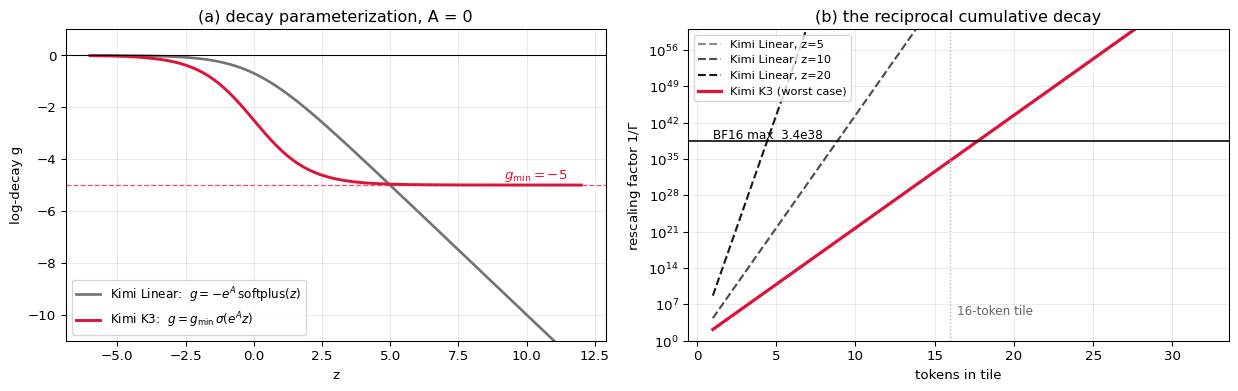

In [13]:
# ---- the overflow argument, in numbers ----
def softplus(x): return np.log1p(np.exp(x))

print("Why the lower bound exists: 1/Gamma over a 16-token tile\n")
print(f"{'z':>6} | {'Kimi Linear alpha':>18} {'1/Gamma':>16} | {'K3 alpha':>10} {'1/Gamma':>14}")
print("-" * 78)
BF16_MAX = 3.39e38
for zz in [0.0, 2.0, 5.0, 10.0, 20.0, 50.0]:
    g_kl = -softplus(zz);      a_kl = np.exp(g_kl); r_kl = np.exp(-16 * g_kl)
    g_k3 = G_MIN * sigmoid(zz); a_k3 = np.exp(g_k3); r_k3 = np.exp(-16 * g_k3)
    flag = "  <-- OVERFLOWS BF16" if r_kl > BF16_MAX else ""
    print(f"{zz:6.0f} | {a_kl:18.3e} {r_kl:16.2e} | {a_k3:10.4f} {r_k3:14.2e}{flag}")
print("-" * 78)
print(f"BF16 max representable      = {BF16_MAX:.2e}")
print(f"K3 worst case = e^(-16*g_min) = e^{-16*G_MIN:.0f} = {np.exp(-16*G_MIN):.2e}   "
      f"-> {np.exp(-16*G_MIN) < BF16_MAX}, always safe")

# ---- Figure 3(a) of the report, reproduced ----
zz = np.linspace(-6, 12, 400)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(zz, -softplus(zz), color="0.45", lw=2, label=r"Kimi Linear:  $g=-e^{A}\,\mathrm{softplus}(z)$")
ax[0].plot(zz, G_MIN * sigmoid(zz), color="crimson", lw=2.2, label=r"Kimi K3:  $g=g_{\min}\,\sigma(e^{A}z)$")
ax[0].axhline(G_MIN, ls="--", color="crimson", lw=1, alpha=.7)
ax[0].axhline(0, color="k", lw=.8)
ax[0].text(11.5, G_MIN + .25, r"$g_{\min}=-5$", ha="right", color="crimson", fontsize=10)
ax[0].set(xlabel="z", ylabel="log-decay g", title="(a) decay parameterization, A = 0", ylim=(-11, 1))
ax[0].legend(fontsize=9, loc="lower left"); ax[0].grid(alpha=.25)

tile = np.arange(1, 33)
for zz_, c, lab in [(5.0, "0.55", "Kimi Linear, z=5"), (10.0, "0.3", "Kimi Linear, z=10"),
                    (20.0, "0.1", "Kimi Linear, z=20")]:
    ax[1].semilogy(tile, np.exp(-tile * -softplus(zz_)), color=c, lw=1.6, ls="--", label=lab)
ax[1].semilogy(tile, np.exp(-tile * G_MIN), color="crimson", lw=2.4, label="Kimi K3 (worst case)")
ax[1].axhline(BF16_MAX, color="k", lw=1.2)
ax[1].text(1, BF16_MAX * 3, "BF16 max  3.4e38", fontsize=9)
ax[1].axvline(16, color="0.7", lw=1, ls=":")
ax[1].text(16.4, 1e5, "16-token tile", fontsize=9, color="0.4")
ax[1].set(xlabel="tokens in tile", ylabel=r"rescaling factor $1/\Gamma$",
          title="(b) the reciprocal cumulative decay", ylim=(1, 1e60))
ax[1].legend(fontsize=8.5, loc="upper left"); ax[1].grid(alpha=.25)
plt.tight_layout(); plt.show()

## 6.4 The recurrence, token by token

This is the definition. Eight tokens, and at each one the state is printed **before** and **after** the update, together with the read.

Watch the two occurrences of `"the"` (positions 0 and 4). They entered §4 with *identical* vectors. Position 0 reads from an empty state; position 4 reads from a state that has absorbed four tokens. This is where NoPE stops being a problem — the recurrence itself is what distinguishes them.

In [14]:
def kda_recurrent(P, verbose_steps=None, tok=None):
    '''Reference implementation: equation (1), one token at a time.'''
    Q, K, V, beta, alpha = P["Q"], P["K"], P["V"], P["beta"], P["alpha"]
    n = Q.shape[0]
    S = np.zeros((D_K, D_V))
    O = np.zeros((n, D_V))
    states = []
    for t in range(n):
        S_dec = np.diag(alpha[t]) @ S                       # decay
        Proj  = np.eye(D_K) - beta[t] * np.outer(K[t], K[t])  # erase
        S     = Proj @ S_dec + beta[t] * np.outer(K[t], V[t]) # write
        O[t]  = S.T @ Q[t]                                   # read
        states.append(S.copy())
        if verbose_steps is not None and t in verbose_steps:
            name = tok[t] if tok else f"t{t}"
            print("=" * 78)
            print(f"  t = {t}   token '{name}'    beta = {beta[t]:.4f}    "
                  f"alpha = {np.round(alpha[t], 4)}")
            print("=" * 78)
            show_state(S_dec, "  (1) decayed   Diag(alpha) S_{t-1}")
            print(f"\n  (2) erase with P = I - {beta[t]:.4f} * k k^T,   k = {np.round(K[t],4)}")
            show_state(Proj @ S_dec, "      P @ decayed")
            print(f"\n  (3) write  + {beta[t]:.4f} * k v^T,   v = {np.round(V[t],4)}")
            show_state(beta[t] * np.outer(K[t], V[t]), "      beta k v^T")
            show_state(S, f"  ==> S_{t}")
            print(f"\n  (4) read   o = S^T q,   q = {np.round(Q[t],4)}")
            print(f"      o_{t} = {np.round(O[t], 6)}")
            print(f"      hand check o[{t},0] = column 0 of S . q:")
            print(f"        {expand(S[:, 0], Q[t])}")
            print(f"        = {float(S[:,0] @ Q[t]):+.6f}   array = {O[t,0]:+.6f}   "
                  f"MATCH: {np.isclose(float(S[:,0] @ Q[t]), O[t,0])}")
            print()
    return O, np.stack(states)


O_rec, S_hist = kda_recurrent(p, verbose_steps=[0, 1, 4], tok=tokens)

  t = 0   token 'the'    beta = 0.4364    alpha = [0.833 0.859 0.484 0.67 ]
  (1) decayed   Diag(alpha) S_{t-1}  (4, 4)
                 v0         v1         v2         v3
       k0   +0.0000    +0.0000    +0.0000    +0.0000
       k1   +0.0000    +0.0000    +0.0000    +0.0000
       k2   +0.0000    +0.0000    +0.0000    +0.0000
       k3   +0.0000    +0.0000    +0.0000    +0.0000

  (2) erase with P = I - 0.4364 * k k^T,   k = [-0.206 -0.559 -0.772 -0.224]
      P @ decayed  (4, 4)
                 v0         v1         v2         v3
       k0   +0.0000    +0.0000    +0.0000    +0.0000
       k1   +0.0000    +0.0000    +0.0000    +0.0000
       k2   +0.0000    +0.0000    +0.0000    +0.0000
       k3   +0.0000    +0.0000    +0.0000    +0.0000

  (3) write  + 0.4364 * k v^T,   v = [-0.019 -0.139 -0.181  0.207]
      beta k v^T  (4, 4)
                 v0         v1         v2         v3
       k0   +0.0017    +0.0125    +0.0163    -0.0187
       k1   +0.0045    +0.0338    +0.0443    -0

all eight reads

o_tilde (head 0)  (8, 4)
                 v0         v1         v2         v3
    0:the   -0.0034    -0.0256    -0.0335    +0.0383
    1:cat   +0.0006    +0.0050    +0.0067    -0.0079
    2:sat   +0.0588    +0.0439    +0.0838    -0.0835
     3:on   -0.0106    +0.0333    -0.0678    -0.0080
    4:the   -0.0106    -0.0027    -0.0472    +0.0272
    5:mat   +0.0159    -0.0222    -0.0414    +0.0692
    6:and   +0.0104    +0.0499    -0.0324    -0.0448
  7:slept   +0.0094    +0.0111    +0.0396    -0.0634

--- the two copies of 'the' ---
  input  X0[0] = [-0.252  0.038 -0.09   0.532 -0.937  0.386  0.441 -0.733]
  input  X0[4] = [-0.252  0.038 -0.09   0.532 -0.937  0.386  0.441 -0.733]   identical: True
  output o[0]  = [-0.003 -0.026 -0.034  0.038]
  output o[4]  = [-0.011 -0.003 -0.047  0.027]   identical: False

  Identical inputs, different outputs. The recurrence supplied the order
  information that NoPE declined to put in the embedding.


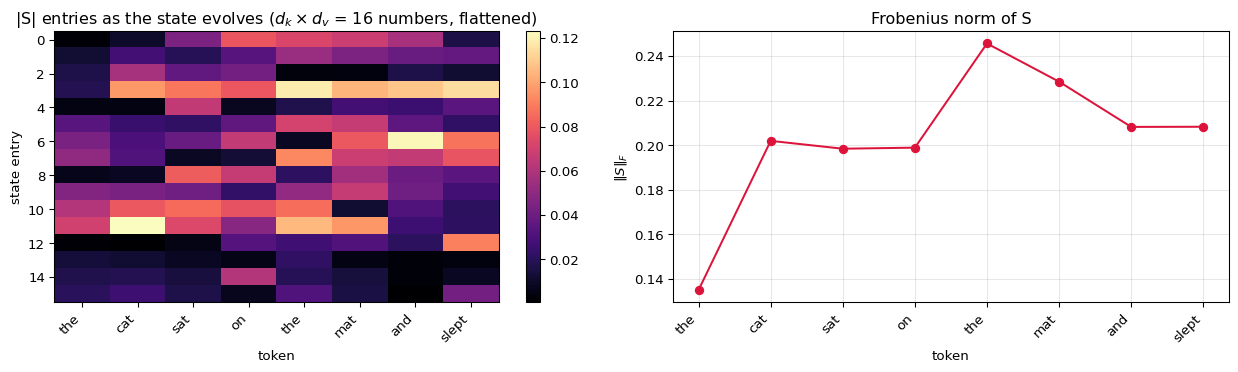

The state is 4x4 = 16 numbers at token 0 and still 16 numbers
at token 8 -- and would still be 16 numbers at token 1,000,000.


In [15]:
print("all eight reads\n")
show_mat(O_rec, "o_tilde (head 0)", rows=rowlab, cols=[f"v{j}" for j in range(D_V)])

print("\n--- the two copies of 'the' ---")
print(f"  input  X0[0] = {np.round(X0[0], 4)}")
print(f"  input  X0[4] = {np.round(X0[4], 4)}   identical: {np.allclose(X0[0], X0[4])}")
print(f"  output o[0]  = {np.round(O_rec[0], 4)}")
print(f"  output o[4]  = {np.round(O_rec[4], 4)}   identical: {np.allclose(O_rec[0], O_rec[4])}")
print()
print("  Identical inputs, different outputs. The recurrence supplied the order")
print("  information that NoPE declined to put in the embedding.")

# state magnitude over time
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
im = ax[0].imshow(np.abs(S_hist).reshape(T, -1).T, cmap="magma", aspect="auto")
ax[0].set(title=r"|S| entries as the state evolves ($d_k \times d_v$ = 16 numbers, flattened)",
          xlabel="token", ylabel="state entry")
ax[0].set_xticks(range(T)); ax[0].set_xticklabels(tokens, rotation=45, ha="right")
plt.colorbar(im, ax=ax[0])
ax[1].plot(np.linalg.norm(S_hist.reshape(T, -1), axis=1), "o-", color="crimson")
ax[1].set(title="Frobenius norm of S", xlabel="token", ylabel=r"$\|S\|_F$")
ax[1].set_xticks(range(T)); ax[1].set_xticklabels(tokens, rotation=45, ha="right")
ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"The state is {D_K}x{D_V} = {D_K*D_V} numbers at token 0 and still {D_K*D_V} numbers")
print(f"at token 8 -- and would still be {D_K*D_V} numbers at token 1,000,000.")

## 6.5 The chunkwise parallel form — what the GPU actually runs

The recurrence above is serial in $t$. A GPU wants wide uniform parallelism. The chunkwise form is **serial across chunks of size $C$, fully parallel inside one**.

### The quantities

Within a chunk, let $\gamma^{r} = \prod_{j=1}^{r}\alpha^{j}$ be the cumulative decay from the chunk start, and $\Gamma^{1\to C}$ the $C \times d_k$ matrix stacking $\gamma^1 \dots \gamma^C$.

$$\tilde V = U - W S_{[t]}, \qquad A = \mathrm{Tril}\Big[(Q \odot \Gamma)(K / \Gamma)^\top\Big]$$

$$\boxed{\;O_{[t]} = \underbrace{(\Gamma \odot Q)\,S_{[t]}}_{\text{inter-chunk}} \;+\; \underbrace{A\,\tilde V}_{\text{intra-chunk}}\;}$$

### Where $U$ and $W$ come from — the UT transform

Define the *normalised* state $\hat S_r = \mathrm{Diag}(1/\gamma^r) S_r$. Substituting into the recurrence and using $\mathrm{Diag}(u)(I - \beta k k^\top) = \big(I - \beta (u\odot k)(k/u)^\top\big)\mathrm{Diag}(u)$ gives

$$\hat S_r = \hat S_{r-1} + \underbrace{(k_r/\gamma^r)}_{\text{"}K/\Gamma\text{"}}\, u_r^\top, \qquad
u_r^\top = \beta_r\Big(v_r^\top - (k_r \odot \gamma^r)^\top \hat S_{r-1}\Big)$$

so every write is a rank-1 update whose magnitude depends on all *earlier* writes in the chunk. Collecting the $u_r$ into a matrix gives a triangular linear system:

$$(I + P)\,\tilde V = \mathrm{Diag}(\beta)\big(V - (K\odot\Gamma)S_{[t]}\big), \qquad P = \mathrm{tril}\Big(\mathrm{Diag}(\beta)(K\odot\Gamma)(K/\Gamma)^\top,\,-1\Big)$$

Inverting once per chunk:
$$T = (I+P)^{-1}\mathrm{Diag}(\beta), \qquad U = T V, \qquad W = T(K \odot \Gamma)$$

### Two details that are easy to get wrong

* **The diagonal of $A$ is kept**, not masked. Each output reads the state *after* its own token's update, so $A_{rr} \ne 0$.
* **The query side gets $\odot\,\Gamma$ and the key side gets $/\,\Gamma$.** Their product recovers $\gamma^{j+1 \to r}$ — the decay accumulated strictly *between* the two positions. That is the whole trick: a pairwise decay expressed as a ratio of two cumulative products, so it can be folded into the operands of a single matmul.

Everything below is verified against §6.4 at the end.

In [16]:
def kda_chunkwise(P, C=CHUNK, verbose_chunks=None, tok=None):
    Q, K, V, beta, alpha = P["Q"], P["K"], P["V"], P["beta"], P["alpha"]
    n = Q.shape[0]
    S = np.zeros((D_K, D_V))
    O = np.zeros((n, D_V))
    for ci in range(n // C):
        sl  = slice(ci * C, (ci + 1) * C)
        a, Qc, Kc, Vc, bc = alpha[sl], Q[sl], K[sl], V[sl], beta[sl]
        Gam = np.cumprod(a, axis=0)                     # gamma^{1->r}
        Kq, Kk, Qg = Kc * Gam, Kc / Gam, Qc * Gam       # K(x)Gamma, K/Gamma, Q(x)Gamma
        Pm  = np.tril(np.diag(bc) @ (Kq @ Kk.T), -1)
        Tm  = np.linalg.inv(np.eye(C) + Pm) @ np.diag(bc)
        U, Wm = Tm @ Vc, Tm @ Kq
        Vt  = U - Wm @ S
        Am  = np.tril(Qg @ Kk.T)
        inter, intra = Qg @ S, Am @ Vt
        O[sl] = inter + intra
        S_new = np.diag(Gam[-1]) @ (S + Kk.T @ Vt)

        if verbose_chunks is not None and ci in verbose_chunks:
            lab = [f"{ci*C+i}:{tok[ci*C+i]}" for i in range(C)] if tok else None
            print("=" * 78)
            print(f"  CHUNK {ci}   tokens {ci*C}..{ci*C+C-1}")
            print("=" * 78)
            show_mat(a,   "alpha inside the chunk", rows=lab, cols=[f"k{j}" for j in range(D_K)])
            print()
            show_mat(Gam, "Gamma = cumprod(alpha, axis=0)", rows=lab, cols=[f"k{j}" for j in range(D_K)])
            print(f"\n  hand check Gamma[2,0] = alpha[0,0]*alpha[1,0]*alpha[2,0]")
            print(f"    = {a[0,0]:.6f} * {a[1,0]:.6f} * {a[2,0]:.6f} = {a[0,0]*a[1,0]*a[2,0]:.6f}"
                  f"   array = {Gam[2,0]:.6f}")
            print()
            show_state(S, "  S_[t] entering this chunk")
            print()
            show_mat(Qg, "Q (x) Gamma", rows=lab, cols=[f"k{j}" for j in range(D_K)])
            print()
            show_mat(Kk, "K / Gamma", rows=lab, cols=[f"k{j}" for j in range(D_K)])
            print()
            show_mat(Kq, "K (x) Gamma   (key side of the UT system)", rows=lab,
                     cols=[f"k{j}" for j in range(D_K)])
            print("\n  ratio check: (Q(x)Gamma)[3] . (K/Gamma)[1]  should carry gamma^{2->3}")
            ratio = Gam[3] / Gam[1]
            print(f"    Gamma[3]/Gamma[1] = {np.round(ratio,6)}")
            print(f"    alpha[2]*alpha[3] = {np.round(a[2]*a[3],6)}   MATCH: "
                  f"{np.allclose(ratio, a[2]*a[3])}")
            print()
            show_mat(Pm, "P = tril(Diag(beta) (K(x)Gamma)(K/Gamma)^T, -1)", rows=lab, cols=lab)
            print()
            show_mat(Tm, "T = (I+P)^-1 Diag(beta)", rows=lab, cols=lab)
            print()
            show_mat(U,  "U = T V",            rows=lab, cols=[f"v{j}" for j in range(D_V)])
            print()
            show_mat(Wm, "W = T (K(x)Gamma)",  rows=lab, cols=[f"k{j}" for j in range(D_K)])
            print()
            show_mat(Vt, "V~ = U - W S_[t]  (the actual rank-1 write magnitudes)",
                     rows=lab, cols=[f"v{j}" for j in range(D_V)])
            print()
            show_mat(Am, "A = Tril[(Q(x)Gamma)(K/Gamma)^T]   -- diagonal KEPT",
                     rows=lab, cols=lab)
            print(f"\n  A is lower-triangular INCLUDING the diagonal: A[0,0] = {Am[0,0]:+.6f} != 0")
            print(f"  (each output reads the state AFTER its own token's update)")
            print()
            show_mat(inter, "inter-chunk  (Gamma(x)Q) S_[t]", rows=lab, cols=[f"v{j}" for j in range(D_V)])
            print()
            show_mat(intra, "intra-chunk  A V~",              rows=lab, cols=[f"v{j}" for j in range(D_V)])
            print()
            show_mat(inter + intra, "O = inter + intra",      rows=lab, cols=[f"v{j}" for j in range(D_V)])
            print()
            show_state(S_new, "  S out -> next chunk")
            print()
        S = S_new
    return O, S


print("chunk 0 has S_[t] = 0, so the inter-chunk term vanishes and only A V~ survives.")
print("chunk 1 is the interesting one: both terms are live.\n")
O_chunk, S_final = kda_chunkwise(p, verbose_chunks=[0, 1], tok=tokens)

chunk 0 has S_[t] = 0, so the inter-chunk term vanishes and only A V~ survives.
chunk 1 is the interesting one: both terms are live.

  CHUNK 0   tokens 0..3
alpha inside the chunk  (4, 4)
                 k0         k1         k2         k3
    0:the   +0.8333    +0.8593    +0.4841    +0.6705
    1:cat   +0.8103    +0.7733    +0.5788    +0.6748
    2:sat   +0.8463    +0.6177    +0.7157    +0.6788
     3:on   +0.8417    +0.6805    +0.6742    +0.6772

Gamma = cumprod(alpha, axis=0)  (4, 4)
                 k0         k1         k2         k3
    0:the   +0.8333    +0.8593    +0.4841    +0.6705
    1:cat   +0.6752    +0.6644    +0.2802    +0.4524
    2:sat   +0.5714    +0.4104    +0.2006    +0.3071
     3:on   +0.4809    +0.2793    +0.1352    +0.2080

  hand check Gamma[2,0] = alpha[0,0]*alpha[1,0]*alpha[2,0]
    = 0.833256 * 0.810283 * 0.846260 = 0.571372   array = 0.571372

  S_[t] entering this chunk  (4, 4)
                 v0         v1         v2         v3
       k0   +0.0000    +

  EQUIVALENCE:  the serial recurrence and the chunkwise kernel
recurrent  (eq. 1, token by token)  (8, 4)
                 v0         v1         v2         v3
    0:the   -0.0034    -0.0256    -0.0335    +0.0383
    1:cat   +0.0006    +0.0050    +0.0067    -0.0079
    2:sat   +0.0588    +0.0439    +0.0838    -0.0835
     3:on   -0.0106    +0.0333    -0.0678    -0.0080
    4:the   -0.0106    -0.0027    -0.0472    +0.0272
    5:mat   +0.0159    -0.0222    -0.0414    +0.0692
    6:and   +0.0104    +0.0499    -0.0324    -0.0448
  7:slept   +0.0094    +0.0111    +0.0396    -0.0634

chunkwise  (eq. 4, two chunks)  (8, 4)
                 v0         v1         v2         v3
    0:the   -0.0034    -0.0256    -0.0335    +0.0383
    1:cat   +0.0006    +0.0050    +0.0067    -0.0079
    2:sat   +0.0588    +0.0439    +0.0838    -0.0835
     3:on   -0.0106    +0.0333    -0.0678    -0.0080
    4:the   -0.0106    -0.0027    -0.0472    +0.0272
    5:mat   +0.0159    -0.0222    -0.0414    +0.0692
    6:

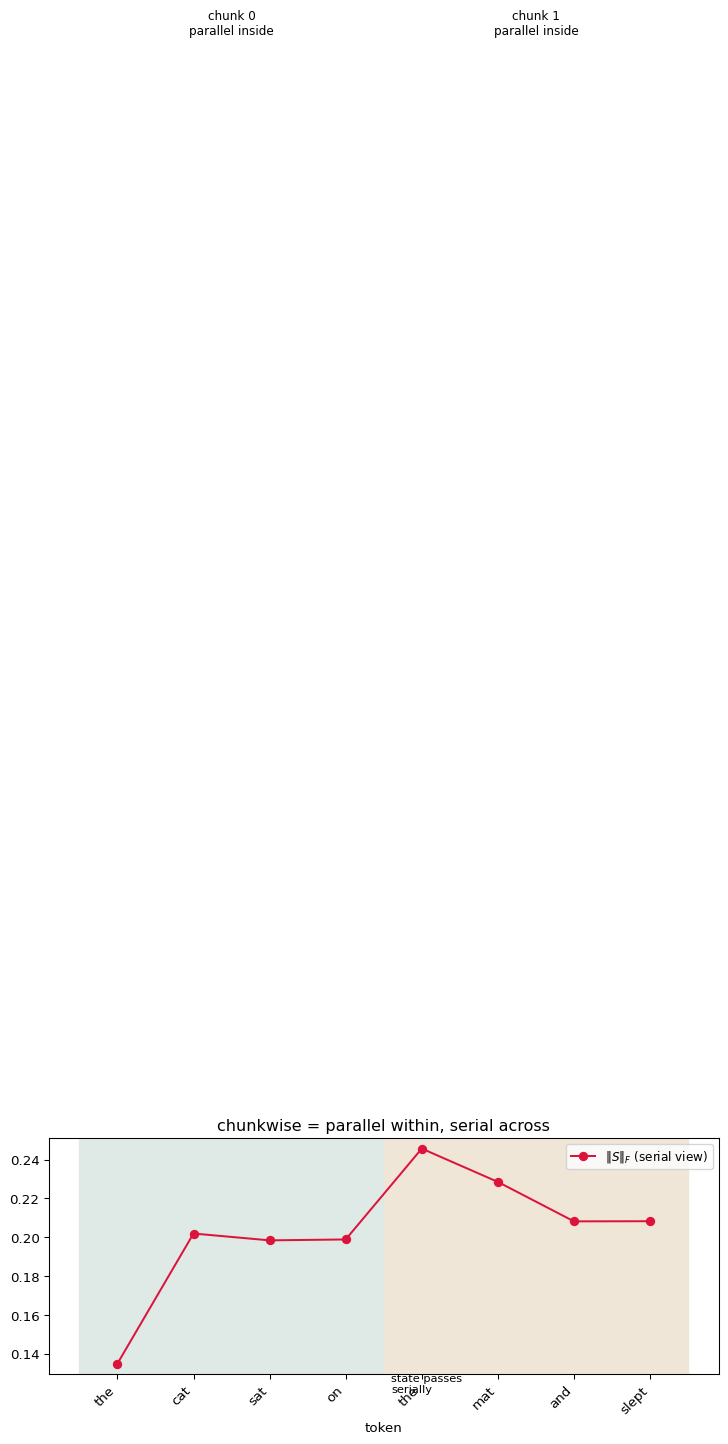

In [17]:
print("=" * 78)
print("  EQUIVALENCE:  the serial recurrence and the chunkwise kernel")
print("=" * 78)
show_mat(O_rec,   "recurrent  (eq. 1, token by token)", rows=rowlab, cols=[f"v{j}" for j in range(D_V)])
print()
show_mat(O_chunk, "chunkwise  (eq. 4, two chunks)",     rows=rowlab, cols=[f"v{j}" for j in range(D_V)])
print()
check("outputs", O_rec, O_chunk, tol=1e-12)
check("final state", S_hist[-1], S_final, tol=1e-12)
print()
print("  Same function, different parallelism. This identity is what FlashKDA exploits:")
print("  because the intra-chunk work is a matmul and the cross-chunk work is a state")
print("  scan, the two can be OVERLAPPED instead of alternating, and the SMs never idle")
print("  during the serial propagation.")

# how the two forms split the work
fig, ax = plt.subplots(figsize=(9, 3.2))
for ci in range(T // CHUNK):
    ax.axvspan(ci * CHUNK - .5, (ci + 1) * CHUNK - .5,
               color=["#dfe9e5", "#f0e6d8"][ci % 2])
    ax.text(ci * CHUNK + CHUNK / 2 - .5, .82, f"chunk {ci}\nparallel inside",
            ha="center", fontsize=9)
ax.plot(range(T), np.linalg.norm(S_hist.reshape(T, -1), axis=1), "o-", color="crimson",
        label=r"$\|S\|_F$ (serial view)")
for ci in range(1, T // CHUNK):
    ax.annotate("", xy=(ci * CHUNK - .5, .35), xytext=(ci * CHUNK - .5, .05),
                arrowprops=dict(arrowstyle="->", lw=2, color="k"))
    ax.text(ci * CHUNK - .4, .12, "state passes\nserially", fontsize=8.5)
ax.set(xticks=range(T), xlabel="token", title="chunkwise = parallel within, serial across")
ax.set_xticklabels(tokens, rotation=45, ha="right"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 6.6 Head-wise RMSNorm, the full-rank gate, and $W_O$

$$y_t = W_o\Big[\sigma(W_g x_t) \odot \mathrm{RMSNorm}(\tilde o_t)\Big]$$

Two changes from Kimi Linear, both stated in §2.1.1 of the report:

* **RMSNorm is applied per head**, before concatenation. Without it, a head whose values happen to be large would dominate the concatenated vector and therefore $W_o$.
* **$W_g$ is full rank.** Kimi Linear used a low-rank output gate; K3 makes it a full $d \times (H d_v)$ projection so every output channel can be modulated independently by the current token. The same change is applied to MLA (§10).

In [18]:
def kda_forward(mod, X, use_chunk=True):
    outs, outs_n = [], []
    for h in range(KDA_HEADS):
        P = mod.head_inputs(X, h)
        O = kda_chunkwise(P)[0] if use_chunk else kda_recurrent(P)[0]
        outs.append(O); outs_n.append(rmsnorm(O))
    Ocat  = np.concatenate(outs,   axis=1)
    Onorm = np.concatenate(outs_n, axis=1)
    gate  = sigmoid(X @ mod.Wg)
    Y     = (gate * Onorm) @ mod.Wo
    return Y, dict(O=Ocat, Onorm=Onorm, gate=gate)


Y_kda, aux = kda_forward(kda_demo, X)
hv = [f"h{h}v{j}" for h in range(KDA_HEADS) for j in range(D_V)]

show_mat(aux["O"], "o_tilde, both heads concatenated", rows=rowlab, cols=hv)
print(f"\n  per-head RMS before norm: head0 = "
      f"{np.sqrt((aux['O'][:, :D_V]**2).mean(1))[:3].round(4)} ...")
print(f"                            head1 = "
      f"{np.sqrt((aux['O'][:, D_V:]**2).mean(1))[:3].round(4)} ...")
print()
show_mat(aux["Onorm"], "RMSNorm applied PER HEAD", rows=rowlab, cols=hv)
_m    = (aux['O'][:, :D_V]**2).mean(1)          # mean square BEFORE the norm
_rms  = np.sqrt((aux['Onorm'][:, :D_V]**2).mean(1))
_pred = np.sqrt(_m / (_m + 1e-6))               # what the eps predicts exactly
print(f"\n  head 0, per token:\n")
print(f"  {'token':>9}  {'mean sq before':>15}  {'rms after':>11}  {'sqrt(m/(m+eps))':>16}")
print("  " + "-" * 58)
for _t in range(T):
    print(f"  {rowlab[_t]:>9}  {_m[_t]:>15.3e}  {_rms[_t]:>11.6f}  {_pred[_t]:>16.6f}")
print("  " + "-" * 58)
print(f"\n  RMSNorm does NOT give exactly 1. It gives sqrt(m/(m+eps)), because")
print(f"  the epsilon sits inside the square root. Matches to floating point:")
print(f"      max|rms - sqrt(m/(m+eps))| = {np.abs(_rms-_pred).max():.2e}   "
      f"MATCH: {np.allclose(_rms, _pred)}")
print(f"\n  The deviation is largest where the activations are smallest -")
print(f"  at mean square {_m.min():.1e} the eps is not negligible beside it and")
print(f"  the rms comes out {_rms.min():.4f}. At realistic activation scales")
print(f"  eps is invisible; here the model is deliberately tiny.")
print()
show_mat(aux["gate"], "sigma(W_g x)  -- full rank, one value per output channel",
         rows=rowlab, cols=hv)
print()
gated = aux["gate"] * aux["Onorm"]
show_elementwise(aux["gate"], aux["Onorm"], gated, "gate", "RMSNorm(o)", "gated", op="*", rows=tokens)
print()
show_matmul(gated, kda_demo.Wo, Y_kda, "gated (8,8)", "W_o (8,8)", "KDA output (8,8)",
            i=1, j=0, rows_A=rowlab)

o_tilde, both heads concatenated  (8, 8)
               h0v0       h0v1       h0v2       h0v3       h1v0       h1v1       h1v2       h1v3
    0:the   -0.0034    -0.0256    -0.0335    +0.0383    -0.0999    +0.0233    +0.0683    +0.0609
    1:cat   +0.0006    +0.0050    +0.0067    -0.0079    -0.0818    -0.0213    +0.0946    +0.0188
    2:sat   +0.0588    +0.0439    +0.0838    -0.0835    -0.0822    -0.0067    +0.0671    -0.0009
     3:on   -0.0106    +0.0333    -0.0678    -0.0080    -0.0226    -0.0082    -0.0107    -0.0206
    4:the   -0.0106    -0.0027    -0.0472    +0.0272    -0.0965    -0.0244    +0.0872    -0.0035
    5:mat   +0.0159    -0.0222    -0.0414    +0.0692    -0.1163    +0.0544    +0.0794    +0.0791
    6:and   +0.0104    +0.0499    -0.0324    -0.0448    +0.0114    -0.0287    -0.0903    -0.1177
  7:slept   +0.0094    +0.0111    +0.0396    -0.0634    +0.0350    -0.0059    -0.0247    -0.0320

  per-head RMS before norm: head0 = [0.029 0.006 0.07 ] ...
                         

---
# 7. Stable LatentMoE — the width axis

Kimi K3 has **896 routed experts per layer with 16 active per token** — a sparsity of 56 — plus 2 always-on shared experts. Kimi K2 had 384 experts with 8 active. Getting from one to the other required three changes, and the report is candid that two of them are bug-fixes for failure modes that only appear at 2.8T scale.

## 7.1 Why a latent space

In a conventional MoE, each selected expert receives the **full** $d$-dimensional token. So the all-to-all communication and the expert-weight traffic both scale with the routing multiplicity $k$. Going from $k=8$ to $k=16$ would double both.

LatentMoE separates the model width from the routed-expert width:

$$z = W^{\downarrow}x \in \mathbb{R}^{\ell}, \qquad \ell = d/2$$

Routed experts live entirely in $\mathbb{R}^{\ell}$; only the shared experts keep a full-width path. In K3, $\ell = 3584$ against $d = 7168$.

$$u = \sum_{i \in \mathcal{T}_k(x)} p_i\, E^{\mathrm{routed}}_i\big(W^{\downarrow}x\big), \qquad
y = \sum_{j=1}^{N_s} E^{\mathrm{shared}}_j(x) \;+\; W^{\uparrow}\,\mathrm{RMSNorm}(u)$$

## 7.2 The two failure modes at extreme sparsity

**Exploding activations.** The routed path composes $W^{\downarrow}$, a gated multi-branch FFN, and $W^{\uparrow}$ — nearly four consecutive matmuls. That chain is ill-conditioned, and at 2.8T parameters it blows up. Fixed by (a) SiTU-GLU inside the expert and (b) the RMSNorm before $W^{\uparrow}$.

**Load balancing.** Balancing ~$10^3$ experts is outside the regime where the fixed-step sign update of auxiliary-loss-free routing behaves. Fixed by Quantile Balancing (§9).

## 7.3 SiTU-GLU

$$\mathrm{SiTU\text{-}GLU}(x) = \underbrace{\Big[\beta_1 \tanh\!\big(\tfrac{W_g x}{\beta_1}\big) \odot \sigma(W_g x)\Big]}_{\text{capped Swish gate}} \odot \underbrace{\Big[\beta_2 \tanh\!\big(\tfrac{W_u x}{\beta_2}\big)\Big]}_{\text{capped up branch}}$$

Compare with what it replaces:

| | gate branch | up branch | bounded? |
|---|---|---|---|
| GLU | $\sigma(x)$ | $x$ | no (up branch unbounded) |
| SwiGLU | $x\,\sigma(x)$ | $x$ | **no** — both factors unbounded |
| SiTU-GLU | $\beta_1\tanh(x/\beta_1)\,\sigma(x)$ | $\beta_2\tanh(x/\beta_2)$ | **yes**, $\le \beta_1\beta_2$ |

Two properties make it a drop-in replacement rather than a different activation:

**Local agreement.** Since $\beta\tanh(z/\beta) = z + O(z^3/\beta^2)$, SiTU-GLU matches SwiGLU **to first order** near the origin. With $\beta_1 = 4, \beta_2 = 25$ the agreement holds to three decimals out to $|x| \approx 1$.

**Hard bound.** Since $|\tanh| < 1$ and $0 < \sigma < 1$:
$$\|\mathrm{SiTU\text{-}GLU}(x)\|_\infty \le \beta_1\beta_2 = 100$$

Why a *smooth* cap and not a clamp: hard-clamping the pre-activations also bounds the output, but with exactly zero gradient past the clamp. $\tanh$ saturates smoothly, so gradients stay nonzero away from the boundary. The report attributes better training behaviour to precisely this.

SwiGLU vs SiTU-GLU on a scalar slice (both branches fed the same x)

       x   Swish(x)       SwiGLU   SiTU gate   SiTU up    SiTU-GLU    ratio
----------------------------------------------------------------------------
   -4.00    -0.0719        0.288     -0.0548    -3.966      0.2173    0.755
   -1.00    -0.2689        0.269     -0.2635    -0.999      0.2633    0.979
   -0.25    -0.1095        0.027     -0.1093    -0.250      0.0273    0.999
    0.00     0.0000        0.000      0.0000     0.000      0.0000    1.000
    0.25     0.1405        0.035      0.1404     0.250      0.0351    0.999
    1.00     0.7311        0.731      0.7162     0.999      0.7158    0.979
    4.00     3.9281       15.712      2.9916     3.966     11.8653    0.755
   20.00    20.0000      400.000      3.9996    16.601     66.3976    0.166  <- capped
   60.00    60.0000     3600.000      4.0000    24.592     98.3675    0.027  <- capped
  200.00   200.0000    40000.000      4.0000    25.000    100.0000    0.

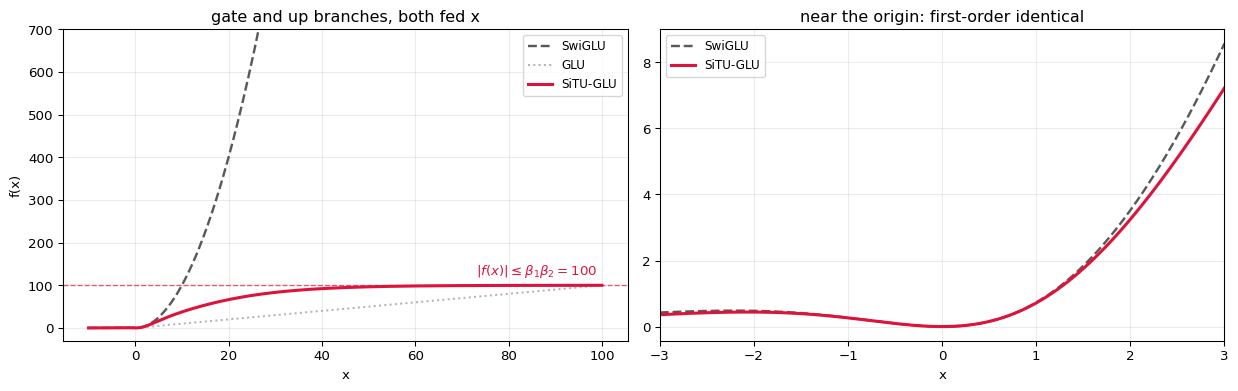

In [19]:
def situ_glu(x, Wg, Wu, b1=BETA1, b2=BETA2, verbose=False):
    g_pre, u_pre = x @ Wg, x @ Wu
    gate = softcap(g_pre, b1) * sigmoid(g_pre)
    up   = softcap(u_pre, b2)
    out  = gate * up
    if verbose:
        print(f"  W_g x        = {np.round(g_pre, 4)}")
        print(f"  b1*tanh(./b1)= {np.round(softcap(g_pre, b1), 4)}   (b1={b1})")
        print(f"  sigma(W_g x) = {np.round(sigmoid(g_pre), 4)}")
        print(f"  gate branch  = {np.round(gate, 4)}")
        print(f"  W_u x        = {np.round(u_pre, 4)}")
        print(f"  up branch    = {np.round(up, 4)}   (b2={b2})")
        print(f"  product      = {np.round(out, 4)}")
    return out


print("SwiGLU vs SiTU-GLU on a scalar slice (both branches fed the same x)\n")
print(f"{'x':>8} {'Swish(x)':>10} {'SwiGLU':>12} {'SiTU gate':>11} {'SiTU up':>9} "
      f"{'SiTU-GLU':>11} {'ratio':>8}")
print("-" * 76)
for xv in [-4, -1, -0.25, 0, 0.25, 1, 4, 20, 60, 200]:
    sw  = swish(xv) * xv
    ga  = softcap(xv, BETA1) * sigmoid(xv)
    upb = softcap(xv, BETA2)
    st  = ga * upb
    ratio = st / sw if abs(sw) > 1e-9 else 1.0
    mark = "  <- capped" if abs(xv) >= 20 else ""
    print(f"{xv:8.2f} {swish(xv):10.4f} {sw:12.3f} {ga:11.4f} {upb:9.3f} {st:11.4f} "
          f"{ratio:8.3f}{mark}")
print("-" * 76)
print(f"bound = b1*b2 = {BETA1}*{BETA2} = {BETA1*BETA2:.0f}")
print(f"at x=200: SwiGLU = {swish(200.)*200:.0f}, SiTU-GLU = {softcap(200.,BETA1)*sigmoid(200.)*softcap(200.,BETA2):.3f}")

# --- Figure 4 of the report, reproduced ---
xs = np.linspace(-10, 100, 900)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(xs, swish(xs) * xs, color="0.35", lw=1.8, ls="--", label="SwiGLU")
ax[0].plot(xs, sigmoid(xs) * xs, color="0.7", lw=1.5, ls=":", label="GLU")
ax[0].plot(xs, softcap(xs, BETA1) * sigmoid(xs) * softcap(xs, BETA2),
           color="crimson", lw=2.3, label="SiTU-GLU")
ax[0].axhline(BETA1 * BETA2, color="crimson", ls="--", lw=1, alpha=.7)
ax[0].text(99, BETA1 * BETA2 + 25, r"$|f(x)|\leq\beta_1\beta_2=100$", ha="right",
           color="crimson", fontsize=10)
ax[0].set(xlabel="x", ylabel="f(x)", title="gate and up branches, both fed x", ylim=(-30, 700))
ax[0].legend(fontsize=9); ax[0].grid(alpha=.25)

xs2 = np.linspace(-3, 3, 400)
ax[1].plot(xs2, swish(xs2) * xs2, color="0.35", lw=1.8, ls="--", label="SwiGLU")
ax[1].plot(xs2, softcap(xs2, BETA1) * sigmoid(xs2) * softcap(xs2, BETA2),
           color="crimson", lw=2.3, label="SiTU-GLU")
ax[1].set(xlabel="x", title="near the origin: first-order identical", xlim=(-3, 3))
ax[1].legend(fontsize=9); ax[1].grid(alpha=.25)
plt.tight_layout(); plt.show()

## 7.4 The routing rule

$$s_i = \sigma(W_r x_i) \in (0,1)^n, \qquad
\mathcal{T}_i = \operatorname{argtop}_k\big(s_i + b\big), \qquad
p_{i,j} = \frac{s_{i,j}}{\sum_{r \in \mathcal{T}_i} s_{i,r}},\quad j \in \mathcal{T}_i$$

Two details that are easy to read past:

**$b$ appears in the selection but not in $p$.** The bias steers *dispatch* without altering the mixture weights or the gradient-based optimisation of the router. Load balancing therefore never distorts what the layer computes — it only changes which experts compute it.

**Routing takes Top-$(k{+}1)$, not Top-$k$.** The first $k$ entries are the routes actually taken; the $(k{+}1)$-th entry is the **cutoff** $\alpha_i$ — the score an expert must exceed to enter token $i$'s Top-$k$. It costs nothing extra here and is exactly what §9 needs, avoiding a separate token-side quantile pass.

In [20]:
class LatentMoE:
    def __init__(self, seed):
        r = np.random.default_rng(seed)
        self.Wdown = xavier(D_MODEL, ELL, r)
        self.Wup   = xavier(ELL, D_MODEL, r)
        self.Wr    = xavier(D_MODEL, N_ROUTED, r)
        self.Eg = [xavier(ELL, D_FF_EXP, r) for _ in range(N_ROUTED)]
        self.Eu = [xavier(ELL, D_FF_EXP, r) for _ in range(N_ROUTED)]
        self.Ed = [xavier(D_FF_EXP, ELL, r) for _ in range(N_ROUTED)]
        self.Sg = [xavier(D_MODEL, D_FF_DENSE, r) for _ in range(N_SHARED)]
        self.Su = [xavier(D_MODEL, D_FF_DENSE, r) for _ in range(N_SHARED)]
        self.Sd = [xavier(D_FF_DENSE, D_MODEL, r) for _ in range(N_SHARED)]
        self.bias = np.zeros(N_ROUTED)

    def route(self, X):
        s = sigmoid(X @ self.Wr)
        biased = s + self.bias
        order  = np.argsort(-biased, axis=1)
        topk   = order[:, :K_TOP]
        cutoff = np.take_along_axis(biased, order[:, K_TOP:K_TOP + 1], axis=1).ravel()
        n = X.shape[0]
        pmat = np.zeros((n, N_ROUTED))
        for t in range(n):
            sel = s[t, topk[t]]
            pmat[t, topk[t]] = sel / sel.sum()
        return s, biased, topk, cutoff, pmat

    def forward(self, X):
        s, biased, topk, cutoff, pmat = self.route(X)
        Z = X @ self.Wdown
        u = np.zeros((X.shape[0], ELL))
        for t in range(X.shape[0]):
            for j in topk[t]:
                u[t] += pmat[t, j] * (situ_glu(Z[t], self.Eg[j], self.Eu[j]) @ self.Ed[j])
        un = rmsnorm(u)
        routed = un @ self.Wup
        shared = np.zeros_like(X)
        for j in range(N_SHARED):
            shared += situ_glu(X, self.Sg[j], self.Su[j]) @ self.Sd[j]
        return shared + routed, dict(s=s, biased=biased, topk=topk, cutoff=cutoff,
                                     p=pmat, Z=Z, u=u, un=un, routed=routed, shared=shared)


moe_demo = LatentMoE(seed=21)
Xm = rmsnorm(Y_kda)                      # what the MoE sublayer would actually see
Ymoe, M = moe_demo.forward(Xm)
elab = [f"E{j}" for j in range(N_ROUTED)]

show_matmul(Xm, moe_demo.Wr, Xm @ moe_demo.Wr, "x (8,8)", "W_r (8,8)", "router logits (8,8)",
            i=0, j=0, rows_A=rowlab)
print()
show_mat(M["s"], "s = sigmoid(W_r x)", rows=rowlab, cols=elab)
print()
print(f"bias b = {M['biased'][0] - M['s'][0]}   (all zero at initialisation)\n")
print(f"{'token':>10} | {'Top-2 experts':>16} | {'cutoff a_i':>11} | mixture weights p")
print("-" * 74)
for t in range(T):
    sel = M["topk"][t]
    pv  = "  ".join(f"E{j}:{M['p'][t,j]:.3f}" for j in sel)
    print(f"{t}:{tokens[t]:<8} | {'E'+str(sel[0])+', E'+str(sel[1]):>16} | "
          f"{M['cutoff'][t]:+11.4f} | {pv}")
print("-" * 74)
t = 0
sel = M["topk"][t]
print(f"\nhand check, token 0, p normalisation over the SELECTED experts only:")
print(f"  s[E{sel[0]}] = {M['s'][t,sel[0]]:.6f},  s[E{sel[1]}] = {M['s'][t,sel[1]]:.6f}")
print(f"  sum        = {M['s'][t,sel].sum():.6f}")
print(f"  p[E{sel[0]}] = {M['s'][t,sel[0]]:.6f} / {M['s'][t,sel].sum():.6f} = "
      f"{M['s'][t,sel[0]]/M['s'][t,sel].sum():.6f}   array = {M['p'][t,sel[0]]:.6f}")
print(f"  p sums to  = {M['p'][t].sum():.6f}")
loads = np.bincount(M["topk"].ravel(), minlength=N_ROUTED)
print(f"\nexpert loads this batch: {loads}   target q = {T*K_TOP//N_ROUTED} each")
print(f"imbalance: max {loads.max()} vs min {loads.min()}   <- section 9 fixes this exactly")

  x (8,8) (8, 8)   @   W_r (8,8) (8, 8)   =   router logits (8,8) (8, 8)
  shape rule: (8 x 8) @ (8 x 8) -> (8 x 8)   inner dim 8 cancels

x (8,8) =
        0:the |   +0.969    +0.246    -0.784    +0.887    +0.459    +1.717    -1.492    -0.463
        1:cat |   -0.787    -0.817    -0.958    -0.807    -0.216    +0.969    -2.025    +0.239
        2:sat |   -0.745    -0.962    -1.492    -0.416    -0.400    +0.203    -1.926    -0.459
         3:on |   +0.566    -0.963    +1.121    -0.055    -1.424    +0.948    +0.804    -1.386
        4:the |   +1.149    -0.539    -0.018    +0.992    -0.349    +1.684    -1.127    -1.085
        5:mat |   +1.289    -0.125    -0.705    +0.708    +0.443    +1.297    -1.692    -0.765
        6:and |   -0.260    -0.675    +1.046    -0.431    -1.409    -0.832    +1.723    -0.742
      7:slept |   -1.099    -0.043    -0.102    -0.157    -0.341    -1.861    +1.742    +0.374

W_r (8,8) =
     -0.558    -0.398    -0.146    +0.157    +0.308    +0.091    -0.270    -0.

In [21]:
print("=" * 78)
print("  DOWN-PROJECTION into the latent space")
print("=" * 78)
show_matmul(Xm, moe_demo.Wdown, M["Z"], "x (8,8)", "W_down (8,4)", "z (8,4)",
            i=0, j=0, rows_A=rowlab,
            note=f"routed experts see {ELL} dims, not {D_MODEL} -- this is what makes k=16 affordable")

print("\n" + "=" * 78)
print("  ONE EXPERT, token 0, worked out")
print("=" * 78)
t, j = 0, int(M["topk"][0][0])
print(f"token 0 '{tokens[0]}' -> expert E{j} with p = {M['p'][t,j]:.4f}")
print(f"  z (latent input) = {np.round(M['Z'][t], 4)}\n")
hgl = situ_glu(M["Z"][t], moe_demo.Eg[j], moe_demo.Eu[j], verbose=True)
out = hgl @ moe_demo.Ed[j]
print(f"  E_down @ product = {np.round(out, 4)}      (back to {ELL} dims)")
print(f"  x p              = {np.round(M['p'][t,j] * out, 4)}")
print(f"\n  bound check: max |SiTU-GLU| = {np.abs(hgl).max():.4f}  <=  b1*b2 = {BETA1*BETA2:.0f}")

  DOWN-PROJECTION into the latent space
  x (8,8) (8, 8)   @   W_down (8,4) (8, 4)   =   z (8,4) (8, 4)
  shape rule: (8 x 8) @ (8 x 4) -> (8 x 4)   inner dim 8 cancels
  routed experts see 4 dims, not 8 -- this is what makes k=16 affordable

x (8,8) =
        0:the |   +0.969    +0.246    -0.784    +0.887    +0.459    +1.717    -1.492    -0.463
        1:cat |   -0.787    -0.817    -0.958    -0.807    -0.216    +0.969    -2.025    +0.239
        2:sat |   -0.745    -0.962    -1.492    -0.416    -0.400    +0.203    -1.926    -0.459
         3:on |   +0.566    -0.963    +1.121    -0.055    -1.424    +0.948    +0.804    -1.386
        4:the |   +1.149    -0.539    -0.018    +0.992    -0.349    +1.684    -1.127    -1.085
        5:mat |   +1.289    -0.125    -0.705    +0.708    +0.443    +1.297    -1.692    -0.765
        6:and |   -0.260    -0.675    +1.046    -0.431    -1.409    -0.832    +1.723    -0.742
      7:slept |   -1.099    -0.043    -0.102    -0.157    -0.341    -1.861    +1.7

## 7.5 The RMSNorm before $W^{\uparrow}$ — the "Normalized LatentMoE" fix

The original LatentMoE applies $W^{\uparrow}$ directly to the aggregate $u$. The problem is that $\|u\|$ varies with **which experts happened to win** and **how the gate weights fell** — two things that change from token to token and from step to step. That hands the up-projection an input whose scale is essentially random.

K3 inserts an RMSNorm between aggregation and up-projection. Beyond stabilising training, the report notes it "consistently improves validation loss and downstream benchmarks" — it is not purely a numerical guard.

The cell below shows the scale variation across just eight tokens.

In [22]:
nrm = np.linalg.norm(M["u"], axis=1)
print("routed aggregate u, before normalisation\n")
show_mat(M["u"], "u", rows=rowlab, cols=[f"l{j}" for j in range(ELL)])
print()
for t in range(T):
    print(f"  {t}:{tokens[t]:<8} experts {tuple(int(_e) for _e in M['topk'][t])}  ||u|| = {nrm[t]:.5f}")
print(f"\n  min ||u|| = {nrm.min():.5f}   max ||u|| = {nrm.max():.5f}   "
      f"ratio = {nrm.max()/nrm.min():.2f}x  across EIGHT tokens")
print()
show_mat(M["un"], "RMSNorm(u)", rows=rowlab, cols=[f"l{j}" for j in range(ELL)])
_mu   = (M['u']**2).mean(1)
_rmsu = np.sqrt((M['un']**2).mean(1))
print(f"\n  rms of each row now : {np.round(_rmsu, 6)}")
print(f"  sqrt(m/(m+eps))     : {np.round(np.sqrt(_mu/(_mu+1e-6)), 6)}")
print(f"  MATCH: {np.allclose(_rmsu, np.sqrt(_mu/(_mu+1e-6)))}"
      f"   (not exactly 1 - the eps inside the sqrt, as in section 3)")
print(f"\n  What matters here is the SPREAD: ||u|| ranged over "
      f"{nrm.max()/nrm.min():.1f}x across these eight")
print(f"  tokens before the norm, and the rows are now on one scale. That is")
print(f"  what stops the up-projection seeing wildly different input magnitudes")
print(f"  depending on which experts a token happened to pick.")
print()
show_matmul(M["un"], moe_demo.Wup, M["routed"], "RMSNorm(u) (8,4)", "W_up (4,8)",
            "routed branch (8,8)", i=0, j=0, rows_A=rowlab)
print()
show_elementwise(M["shared"], M["routed"], Ymoe,
                 "shared (full width)", "routed (via latent)", "MoE output", "+", rows=tokens)

routed aggregate u, before normalisation

u  (8, 4)
                 l0         l1         l2         l3
    0:the   +0.1999    -0.3091    -0.3016    +0.0541
    1:cat   +0.0447    -0.1444    +0.0252    +0.2425
    2:sat   +0.0424    -0.0268    -0.0535    +0.0358
     3:on   +0.0780    -0.8425    +0.4785    +0.3684
    4:the   +0.2508    -0.3155    +0.1232    +0.5136
    5:mat   +0.0195    -0.0471    -0.0379    +0.2216
    6:and   -0.4231    -0.1006    +0.6512    +0.0513
  7:slept   +0.3167    -0.3376    +0.2335    -0.0349

  0:the      experts (6, 0)  ||u|| = 0.47894
  1:cat      experts (1, 6)  ||u|| = 0.28685
  2:sat      experts (1, 0)  ||u|| = 0.08162
  3:on       experts (7, 5)  ||u|| = 1.03951
  4:the      experts (6, 5)  ||u|| = 0.66440
  5:mat      experts (6, 3)  ||u|| = 0.23052
  6:and      experts (7, 1)  ||u|| = 0.78472
  7:slept    experts (2, 7)  ||u|| = 0.51963

  min ||u|| = 0.08162   max ||u|| = 1.03951   ratio = 12.74x  across EIGHT tokens

RMSNorm(u)  (8, 4)
       

---
# 9. Quantile Balancing

The load imbalance from §7.4, fixed exactly. This is the part of the paper with a real derivation behind it, so it is worth doing properly.

## 9.1 From balanced assignment to a quantile

Let $s \in \mathbb{R}^{m \times n}$ collect router scores for $m$ tokens over $n$ experts, and $x_{i,j} \in \{0,1\}$ indicate assignment. The **maximum-score balanced assignment** is

$$\max_{x_{i,j} \in \{0,1\}} \sum_{i,j} x_{i,j}s_{i,j}
\quad\text{s.t.}\quad \sum_j x_{i,j} = k, \qquad \sum_i x_{i,j} = \frac{mk}{n}$$

Relaxing to $x_{i,j} \in [0,1]$ gives a linear program whose optimum is **integral** (bipartite $b$-matching), so the relaxation is exact. Introducing multipliers $\alpha_i$ (token side) and $\beta_j$ (expert side), applying the minimax theorem, and eliminating $x$ gives the convex dual

$$\min_{\alpha,\beta}\; \mathcal{L}(\alpha,\beta) = \sum_{i,j}\max\big(0,\; s_{i,j} - \alpha_i - \beta_j\big) \;+\; k\sum_i \alpha_i \;+\; \frac{mk}{n}\sum_j \beta_j$$

Each coordinate subproblem is **piecewise linear**, so its minimiser is an order statistic. For a fixed $\beta$, token $i$ solves $\min_\alpha k\alpha + \sum_j \max(0, s_{i,j}-\beta_j-\alpha)$, whose slope is $k$ minus the number of margins exceeding $\alpha$ — minimised when exactly $k$ margins lie above. Symmetrically for $\beta$. Both are the same quantile, along different axes:

$$\alpha_i^* = \mathrm{quantile}_{1-k/n}\big(s_i - \beta\big), \qquad
\beta_j^* = \mathrm{quantile}_{1-k/n}\big(s_{:,j} - \alpha\big)$$

which is where the method gets its name.

## 9.2 The update actually used

$$\widehat b_j \leftarrow -\,\mathrm{quantile}_{1-k/n}\big(s_{:,j} - \alpha^{(t)}\big), \qquad
b^{(t+1)} \leftarrow \widehat b - \mathrm{mean}(\widehat b)\,\mathbf{1}$$

with $\alpha^{(t)}$ the Top-$(k{+}1)$ cutoff already computed during routing. Setting $-\widehat b_j$ to the $(q{+}1)$-th largest margin leaves **exactly $q$ margins above the threshold** — i.e. exactly $q$ tokens routed to expert $j$. Mean-centring is free: Top-$k$ is invariant to a common offset.

## 9.3 The connection to what it replaces

Differentiating the expert-side term:

$$\frac{\partial \mathcal{L}}{\partial \beta_j} = \frac{mk}{n} - \sum_{i=1}^m \mathbb{1}\big[s_{i,j}-\alpha_i-\beta_j > 0\big] = \text{target load} - \text{observed load}$$

A **SignSGD step on this gradient is exactly** the fixed-step sign update $b_j^{(t+1)} = b_j^{(t)} + \gamma\,\mathrm{sign}(\bar\ell - \ell_j)$ of DeepSeek-V3-style auxiliary-loss-free balancing. It keeps only the *direction* of the load error. QB jumps straight to the exact coordinate minimiser of the same dual objective.

That explains both reported properties at once: **no learning-rate-like $\gamma$ to tune**, and **equilibration within a few steps even for ~$10^3$ experts**.

*(Causality: the new bias applies from the next step — a batch is never routed with a bias derived from itself. At inference the bias is frozen, so serving is a plain Top-$k$ with a constant vector.)*

In [23]:
m, n, k = T, N_ROUTED, K_TOP
q = m * k // n
print(f"m = {m} tokens, n = {n} experts, k = {k}  ->  target load q = mk/n = {q}\n")

margins = M["s"] - M["cutoff"][:, None]
show_mat(margins, "margins  s[i,j] - alpha_i", rows=rowlab, cols=elab)
print("\n  a margin > 0 means the expert beat the cutoff, i.e. it was selected.")
print(f"  positives per column: {(margins > 1e-12).sum(0)}   = the loads {loads}\n")

srt = np.sort(margins, axis=0)[::-1]
print("each expert's margins, sorted downward\n")
print(f"{'rank':>6} " + "  ".join(f"{e:>9}" for e in elab))
print("-" * (7 + 11 * n))
for r in range(m):
    tag = "  <== (q+1)" if r == q else ""
    print(f"{r+1:>6} " + "  ".join(f"{srt[r,j]:+9.4f}" for j in range(n)) + tag)
print("-" * (7 + 11 * n))

bhat = -srt[q]
bnew = bhat - bhat.mean()
print(f"\nb_hat = -(q+1)-th largest margin = {np.round(bhat, 5)}")
print(f"mean  = {bhat.mean():+.6f}")
print(f"b_new = b_hat - mean            = {np.round(bnew, 5)}")

biased_next = M["s"] + bnew
topk_next = np.argsort(-biased_next, axis=1)[:, :K_TOP]
loads_next = np.bincount(topk_next.ravel(), minlength=N_ROUTED)
print()
show_mat(biased_next, "s + b_new  (what the NEXT step will route on)", rows=rowlab, cols=elab)
print()
print(f"{'':>16}" + "  ".join(f"{e:>5}" for e in elab) + "   spread")
print(f"{'load before':>16}" + "  ".join(f"{v:>5}" for v in loads) +
      f"   {loads.max()-loads.min()}")
print(f"{'load after':>16}" + "  ".join(f"{v:>5}" for v in loads_next) +
      f"   {loads_next.max()-loads_next.min()}")
print(f"{'target':>16}" + "  ".join(f"{q:>5}" for _ in elab))
print(f"\nexactly balanced after ONE update: {np.all(loads_next == q)}")
print(f"spread went {loads.max()-loads.min()} -> {loads_next.max()-loads_next.min()}, "
      f"but not all the way to 0.")
print("The next cell explains why -- and it is not a bug.")

m = 8 tokens, n = 8 experts, k = 2  ->  target load q = mk/n = 2

margins  s[i,j] - alpha_i  (8, 8)
                 E0         E1         E2         E3         E4         E5         E6         E7
    0:the   +0.0524    -0.4334    -0.2457    +0.0000    -0.0692    -0.1663    +0.2271    -0.4060
    1:cat   +0.0000    +0.1084    -0.4920    -0.1822    -0.3328    -0.2285    +0.0096    -0.3342
    2:sat   +0.0785    +0.0886    -0.2192    -0.1221    -0.3930    -0.1840    +0.0000    -0.1834
     3:on   -0.2687    +0.0000    -0.0353    -0.3110    -0.3170    +0.0440    -0.3396    +0.3283
    4:the   +0.0000    -0.2818    -0.0989    -0.0298    -0.1679    +0.0498    +0.1740    -0.0131
    5:mat   +0.0000    -0.3682    -0.1909    +0.1127    -0.0551    -0.1157    +0.2231    -0.3249
    6:and   -0.4600    +0.0238    +0.0000    -0.4809    -0.4739    -0.1188    -0.6131    +0.1848
  7:slept   -0.1765    +0.0000    +0.0978    -0.3967    -0.3141    -0.1360    -0.4982    +0.0666

  a margin > 0 means the e

### Why one update is not a fixed point, and what "balanced" really means here

Two separate things are going on, and it is worth pulling them apart.

**1. The update is one coordinate step, not the joint optimum.** The margins were computed against $\alpha^{(t)}$, the cutoffs produced by routing with the **old** bias. Change $b$ and the cutoffs move too: demoting an expert frees a slot, which lowers the cutoff for the tokens that were using it, which changes every other expert's margins. Eq. 14 is therefore one block-coordinate step of an alternating minimisation. Algorithm 1 in Appendix C of the report is the full solver:

$$\alpha \leftarrow \mathrm{desc\_sort}(s - \beta,\ \mathrm{axis}{=}1)_{[:,\,k:k+1]}, \qquad
\beta \leftarrow \mathrm{desc\_sort}(s - \alpha,\ \mathrm{axis}{=}0)_{[mk/n\,:\,mk/n+1]}$$

That this is deliberately *not* iterated during training is a causality requirement: the new bias takes effect only at the *next* step, so a batch is never routed with a bias derived from itself.

**2. With 8 tokens, perfect balance is not a meaningful target.** The load is an integer. A target of $q = 2$ means one token moving changes an expert's load by 50%. The quantity that actually matters is the **relative** imbalance $(\ell_{\max} - \ell_{\min}) / q$, and that is what shrinks — the third cell below measures it as the batch grows.

This is the regime QB is built for: in K3 a batch is millions of tokens against 896 experts, so $q$ is large and the granularity argument above disappears. The report's claim is that the histogram estimator leaves "no measurable residual load imbalance" at that scale — not that a batch of 8 can be split perfectly.

What is genuinely absent, at any batch size, is a **step size**. The sign-update method QB replaces has a $\gamma$ trading adaptation speed against load oscillation. QB jumps to the exact coordinate minimiser, so there is nothing to tune — that is the claim the next cells test.

In [24]:
def qb_alternating(s, k=K_TOP, n_iter=6, verbose=True):
    # Algorithm 1 of the report: alternate the token-side and expert-side quantiles.
    m_, n_ = s.shape
    q_ = m_ * k // n_
    beta = np.zeros(n_)
    for it in range(n_iter):
        a    = np.sort(s - beta, axis=1)[:, ::-1][:, k]        # (k+1)-th largest per TOKEN
        beta = np.sort(s - a[:, None], axis=0)[::-1][q_]       # (q+1)-th largest per EXPERT
        ld   = np.bincount(np.argsort(-(s - beta), axis=1)[:, :k].ravel(), minlength=n_)
        if verbose:
            print(f"  iter {it+1}:  loads = {ld}   spread = {ld.max()-ld.min()}")
    return beta


print("ALGORITHM 1 -- the alternating solver  (bias b = -beta)\n")
beta_star = qb_alternating(M["s"], n_iter=6)
b_star = -beta_star; b_star = b_star - b_star.mean()
ld_star = np.bincount(np.argsort(-(M["s"] + b_star), axis=1)[:, :K_TOP].ravel(), minlength=N_ROUTED)
print(f"\n  converged bias b* = {np.round(b_star, 5)}")
print(f"  loads             = {ld_star}   (target {q} each, spread {ld_star.max()-ld_star.min()})")
print(f"\n  It converges in ONE iteration and then stops moving -- but not to a perfect split.")
print(f"  With q = {q}, a single token is 50% of an expert's quota. See the scaling cell below.")

ALGORITHM 1 -- the alternating solver  (bias b = -beta)

  iter 1:  loads = [3 2 2 1 2 2 1 3]   spread = 2
  iter 2:  loads = [2 2 2 2 2 2 1 3]   spread = 2
  iter 3:  loads = [2 2 2 2 2 2 1 3]   spread = 2
  iter 4:  loads = [2 2 2 2 2 3 1 2]   spread = 2
  iter 5:  loads = [2 2 2 2 2 3 1 2]   spread = 2
  iter 6:  loads = [2 2 2 2 2 3 1 2]   spread = 2

  converged bias b* = [-0.011 -0.035  0.025  0.042  0.157  0.105 -0.185 -0.098]
  loads             = [2 2 2 2 2 3 1 2]   (target 2 each, spread 2)

  It converges in ONE iteration and then stops moving -- but not to a perfect split.
  With q = 2, a single token is 50% of an expert's quota. See the scaling cell below.


In [25]:
print("TRAINING-TIME VIEW -- one Eq.14 update per step, bias carried forward\n")
b_run, spread_hist = np.zeros(N_ROUTED), []
for step in range(8):
    biased = M["s"] + b_run
    order  = np.argsort(-biased, axis=1)
    tk     = order[:, :K_TOP]
    cut    = np.take_along_axis(biased, order[:, K_TOP:K_TOP+1], axis=1).ravel()
    ld     = np.bincount(tk.ravel(), minlength=N_ROUTED)
    spread_hist.append(int(ld.max() - ld.min()))
    print(f"  step {step+1}: loads = {ld}   spread = {ld.max()-ld.min()}")
    mg    = M["s"] - cut[:, None]
    bh    = -np.sort(mg, axis=0)[::-1][q]
    b_run = bh - bh.mean()                      # takes effect from the NEXT step

print(f"\n  spread over steps: {spread_hist}")
print(f"  it settles after {spread_hist.index(min(spread_hist))+1} step(s) and stays there --")
print(f"  no oscillation, which is the failure mode a fixed-step sign update has to trade against.")

TRAINING-TIME VIEW -- one Eq.14 update per step, bias carried forward

  step 1: loads = [2 3 1 1 0 2 4 3]   spread = 4
  step 2: loads = [2 2 2 1 3 2 1 3]   spread = 2
  step 3: loads = [2 2 2 2 2 3 1 2]   spread = 2
  step 4: loads = [2 2 2 2 2 2 1 3]   spread = 2
  step 5: loads = [2 2 2 2 2 3 1 2]   spread = 2
  step 6: loads = [2 2 2 2 2 3 1 2]   spread = 2
  step 7: loads = [2 2 2 2 2 3 1 2]   spread = 2
  step 8: loads = [2 2 2 2 2 3 1 2]   spread = 2

  spread over steps: [4, 2, 2, 2, 2, 2, 2, 2]
  it settles after 2 step(s) and stays there --
  no oscillation, which is the failure mode a fixed-step sign update has to trade against.


THE QUANTITY THAT ACTUALLY MATTERS: relative imbalance vs batch size

  m =     8  q =    2   no balancing:  2.000   with QB:  1.500   (absolute spread 3)
  m =    16  q =    4   no balancing:  1.250   with QB:  0.750   (absolute spread 3)
  m =    32  q =    8   no balancing:  0.875   with QB:  0.875   (absolute spread 7)
  m =    64  q =   16   no balancing:  0.438   with QB:  0.375   (absolute spread 6)
  m =   128  q =   32   no balancing:  0.344   with QB:  0.094   (absolute spread 3)
  m =   256  q =   64   no balancing:  0.422   with QB:  0.125   (absolute spread 8)
  m =   512  q =  128   no balancing:  0.203   with QB:  0.086   (absolute spread 11)
  m =  1024  q =  256   no balancing:  0.168   with QB:  0.035   (absolute spread 9)
  m =  4096  q = 1024   no balancing:  0.054   with QB:  0.017   (absolute spread 17)

  relative imbalance under QB: 1.50 at m=8  ->  0.0166 at m=4096
  K3 trains with m in the millions against 896 experts, far to the right of this plot.


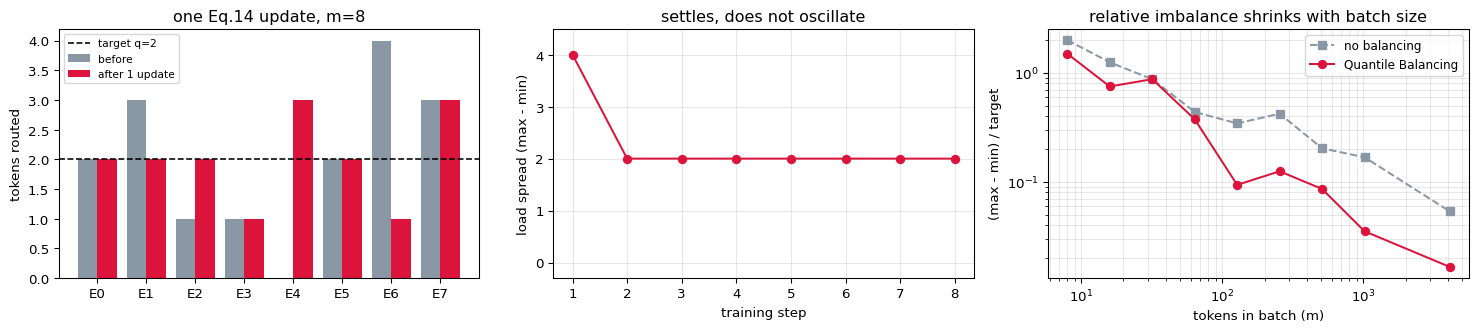

In [26]:
print("THE QUANTITY THAT ACTUALLY MATTERS: relative imbalance vs batch size\n")
rng_qb = np.random.default_rng(7)
sizes  = [8, 16, 32, 64, 128, 256, 512, 1024, 4096]
rel_qb, rel_none, abs_qb = [], [], []
for m_ in sizes:
    sm = sigmoid(rng_qb.normal(0, 1, (m_, N_ROUTED)))
    q_ = m_ * K_TOP // N_ROUTED
    ld0 = np.bincount(np.argsort(-sm, axis=1)[:, :K_TOP].ravel(), minlength=N_ROUTED)
    bq  = -qb_alternating(sm, n_iter=8, verbose=False)
    ld1 = np.bincount(np.argsort(-(sm + bq), axis=1)[:, :K_TOP].ravel(), minlength=N_ROUTED)
    rel_none.append((ld0.max() - ld0.min()) / q_)
    rel_qb.append((ld1.max() - ld1.min()) / q_)
    abs_qb.append(int(ld1.max() - ld1.min()))
    print(f"  m = {m_:>5}  q = {q_:>4}   no balancing: {(ld0.max()-ld0.min())/q_:6.3f}"
          f"   with QB: {(ld1.max()-ld1.min())/q_:6.3f}   (absolute spread {ld1.max()-ld1.min()})")

print(f"\n  relative imbalance under QB: {rel_qb[0]:.2f} at m=8  ->  {rel_qb[-1]:.4f} at m={sizes[-1]}")
print(f"  K3 trains with m in the millions against 896 experts, far to the right of this plot.")

fig, ax = plt.subplots(1, 3, figsize=(15.5, 3.6))
xx = np.arange(n)
ax[0].bar(xx - .2, loads, .4, label="before", color="#8a97a5")
ax[0].bar(xx + .2, loads_next, .4, label="after 1 update", color="crimson")
ax[0].axhline(q, ls="--", color="k", lw=1.2, label=f"target q={q}")
ax[0].set(xticks=xx, xticklabels=elab, ylabel="tokens routed", title="one Eq.14 update, m=8")
ax[0].legend(fontsize=8)
ax[1].plot(np.arange(1, len(spread_hist) + 1), spread_hist, "o-", color="crimson")
ax[1].set(xlabel="training step", ylabel="load spread (max - min)",
          ylim=(-.3, max(spread_hist) + .5), title="settles, does not oscillate")
ax[1].grid(alpha=.3)
ax[2].loglog(sizes, np.maximum(rel_none, 1e-3), "s--", color="#8a97a5", label="no balancing")
ax[2].loglog(sizes, np.maximum(rel_qb, 1e-3), "o-", color="crimson", label="Quantile Balancing")
ax[2].set(xlabel="tokens in batch (m)", ylabel="(max - min) / target",
          title="relative imbalance shrinks with batch size")
ax[2].legend(fontsize=9); ax[2].grid(alpha=.3, which="both")
plt.tight_layout(); plt.show()

### At real scale: the histogram estimator

With $m$ in the millions, sharded across data-parallel ranks and gradient-accumulation steps, gathering $O(mn)$ margins for an exact quantile is not viable inside the training loop.

The observation that makes it cheap: the update never needs the margins themselves, only their **per-expert distribution**. So each rank scatter-adds its local values into a per-expert count matrix $H \in \mathbb{N}^{n \times B}$ with no communication, and one integer all-reduce of $nB$ values pools them at the end of the step.

Because counts are **additive**, the pooled histogram is exactly invariant to how tokens were sharded. The estimate is therefore the quantile of the true global batch up to one bin width — *not* an average of per-rank quantiles, which is a different number. With $B = 1000$ the error is a few $10^{-3}$, at a communication cost below 1% of the alternative.

In [27]:
def qb_histogram(margins, cutoffs, n_bins=2000, n_ranks=4):
    '''Same update, computed from a pooled histogram sharded across ranks.'''
    req = -margins                                   # required bias, per report
    lo, hi = req.min() - 1e-6, req.max() + 1e-6
    w = (hi - lo) / n_bins
    H = np.zeros((N_ROUTED, n_bins), dtype=np.int64)
    parts = np.array_split(np.arange(margins.shape[0]), n_ranks)
    for rank in parts:                               # each rank, no communication
        Hl = np.zeros_like(H)
        for i in rank:
            for j in range(N_ROUTED):
                b = min(int((req[i, j] - lo) / w), n_bins - 1)
                Hl[j, b] += 1
        H += Hl                                      # <- the single all-reduce
    # Eq. 14 wants the (q+1)-th order statistic, so that is the rank we read off.
    rank = margins.shape[0] * K_TOP // N_ROUTED + 1
    out = np.zeros(N_ROUTED)
    for j in range(N_ROUTED):
        c = np.cumsum(H[j])
        b = int(np.searchsorted(c, rank))
        prev = c[b - 1] if b > 0 else 0
        frac = np.clip((rank - prev) / max(H[j, b], 1), 0, 1)
        out[j] = lo + (b + frac) * w
    return out - out.mean(), H, w


b_hist, H, binw = qb_histogram(margins, M["cutoff"], n_bins=2000)
print(f"bins = 2000, ranks = 4  ->  one all-reduce of {N_ROUTED}x2000 integers")
print(f"bin width w = {binw:.3e}\n")
print(f"exact     b = {np.round(bnew, 6)}")
print(f"histogram b = {np.round(b_hist, 6)}")
print(f"max |diff|  = {np.abs(bnew - b_hist).max():.3e}   <= bin width w = {binw:.3e}:  "
      f"{np.abs(bnew - b_hist).max() <= binw}")
print()
print("The error is bounded by the bin width because cumulative counts are exact at bin")
print("edges -- the true quantile and its estimate always land in the SAME bin.")
lo2 = np.bincount(np.argsort(-(M['s'] + b_hist), axis=1)[:, :K_TOP].ravel(), minlength=N_ROUTED)
print(f"\nloads with the exact bias    : {loads_next}")
print(f"loads with the histogram bias: {lo2}   identical: {np.array_equal(lo2, loads_next)}")
print("the estimator changes nothing about the routing decision -- only how the")
print("quantile was obtained, at 1/100th of the communication cost.")
print("\ninvariance check -- shard the same tokens differently:")
for nr in [1, 2, 4, 8]:
    bb, _, _ = qb_histogram(margins, M["cutoff"], n_ranks=nr)
    print(f"  {nr} rank(s): b = {np.round(bb, 6)}")
print("  identical regardless of sharding, because counts are additive.")

bins = 2000, ranks = 4  ->  one all-reduce of 8x2000 integers
bin width w = 4.707e-04

exact     b = [-0.011 -0.034  0.025  0.019  0.157  0.105 -0.185 -0.077]
histogram b = [-0.011 -0.034  0.025  0.019  0.158  0.105 -0.185 -0.077]
max |diff|  = 2.825e-04   <= bin width w = 4.707e-04:  True

The error is bounded by the bin width because cumulative counts are exact at bin
edges -- the true quantile and its estimate always land in the SAME bin.

loads with the exact bias    : [2 2 2 1 3 2 1 3]
loads with the histogram bias: [2 2 2 1 3 2 1 3]   identical: True
the estimator changes nothing about the routing decision -- only how the
quantile was obtained, at 1/100th of the communication cost.

invariance check -- shard the same tokens differently:
  1 rank(s): b = [-0.011 -0.034  0.025  0.019  0.158  0.105 -0.185 -0.077]
  2 rank(s): b = [-0.011 -0.034  0.025  0.019  0.158  0.105 -0.185 -0.077]
  4 rank(s): b = [-0.011 -0.034  0.025  0.019  0.158  0.105 -0.185 -0.077]
  8 rank(s): b = [-0.0

---
# 10. Gated MLA — the one global layer per block

Three KDA layers gave position-sensitive, recency-weighted mixing through a fixed-size state. The fourth layer of every block gives **unrestricted content-based access to every earlier token**. The report also places an extra Gated MLA at the very end of the backbone, so the final layer always performs global attention.

## 10.1 The latent KV compression

$$c_t = W_c x_t \in \mathbb{R}^{d_c}, \qquad
k^h_t = W^h_{uk}c_t, \qquad v^h_t = W^h_{uv}c_t$$

Only $c_t$ is cached. The per-head keys and values are **reconstructed on the fly** by the up-projections during attention. That is the whole MLA idea (from DeepSeek-V2): pay $d_c$ per token in cache instead of $2 H d_h$.

## 10.2 NoPE

Unlike Kimi K2, K3 applies **no positional encoding to the MLA queries or keys**. The separation of duties:

* KDA layers → position-sensitive, recency-aware sequence mixing
* MLA layers → unrestricted global *content* interaction

The practical payoff is at context extension time. Going from 64K to 1M requires no RoPE frequency-base retuning and no YaRN interpolation, because there is no positional parameter to adjust.

## 10.3 The gate

$$y_t = W_o\Big[\sigma(W_g x_t) \odot \tilde o_t\Big]$$

Same full-rank gate as KDA, letting each token modulate which channels it reads from global attention.

In [28]:
class GatedMLA:
    def __init__(self, seed):
        r = np.random.default_rng(seed)
        self.Wc  = xavier(D_MODEL, D_C, r)
        self.Wuk = [xavier(D_C, D_H, r) for _ in range(MLA_HEADS)]
        self.Wuv = [xavier(D_C, D_H, r) for _ in range(MLA_HEADS)]
        self.Wq  = [xavier(D_MODEL, D_H, r) for _ in range(MLA_HEADS)]
        self.Wg  = xavier(D_MODEL, MLA_HEADS * D_H, r)
        self.Wo  = xavier(MLA_HEADS * D_H, D_MODEL, r)

    def forward(self, X, verbose=False):
        C = X @ self.Wc
        n = X.shape[0]
        mask = np.tril(np.ones((n, n), dtype=bool))
        outs, info = [], []
        for h in range(MLA_HEADS):
            Kh, Vh = C @ self.Wuk[h], C @ self.Wuv[h]
            Qh = X @ self.Wq[h]
            sc = Qh @ Kh.T / np.sqrt(D_H)
            sc_m = np.where(mask, sc, -np.inf)
            P = softmax(sc_m, axis=1)
            O = P @ Vh
            outs.append(O)
            info.append(dict(K=Kh, V=Vh, Q=Qh, scores=np.where(mask, sc, np.nan), P=P, O=O))
        Ocat = np.concatenate(outs, axis=1)
        gate = sigmoid(X @ self.Wg)
        Y = (gate * Ocat) @ self.Wo
        return Y, dict(C=C, heads=info, Ocat=Ocat, gate=gate)


mla_demo = GatedMLA(seed=31)
Xa = rmsnorm(Ymoe)
Y_mla, A_ = mla_demo.forward(Xa)

print("STEP 1  compress every token to a latent -- THIS is the cache")
show_matmul(Xa, mla_demo.Wc, A_["C"], "x (8,8)", "W_c (8,4)", "c (8,4)", i=0, j=0, rows_A=rowlab)
print()
print("STEP 2  rebuild K and V from the latent (never cached themselves)")
show_matmul(A_["C"], mla_demo.Wuk[0], A_["heads"][0]["K"], "c (8,4)", "W_uk head0 (4,4)",
            "K head0 (8,4)", i=1, j=0, rows_A=rowlab)

STEP 1  compress every token to a latent -- THIS is the cache
  x (8,8) (8, 8)   @   W_c (8,4) (8, 4)   =   c (8,4) (8, 4)
  shape rule: (8 x 8) @ (8 x 4) -> (8 x 4)   inner dim 8 cancels

x (8,8) =
        0:the |   +0.436    +1.087    -0.580    -2.273    -0.855    +0.534    +0.092    +0.321
        1:cat |   +1.545    -0.891    -1.324    -1.314    -0.606    +0.409    +0.151    +0.886
        2:sat |   +1.149    +0.469    -1.000    -1.720    -1.383    +0.461    +0.358    +0.501
         3:on |   +1.781    -1.593    -1.038    -0.829    -0.142    -0.168    +0.256    +0.643
        4:the |   +1.645    -0.886    -1.016    -1.453    -0.837    +0.478    +0.608    +0.253
        5:mat |   +0.799    -0.790    -1.010    -1.903    -0.701    +1.025    +0.661    +0.345
        6:and |   -0.242    -2.062    +0.166    +0.817    +1.617    -0.602    +0.084    -0.106
      7:slept |   +2.177    +0.415    -0.962    -0.438    -0.557    -1.239    -0.047    -0.351

W_c (8,4) =
     +0.570    -0.611    +0.

STEP 3  scores, causal mask, softmax

q k^T / sqrt(d_h)   (NaN = masked)  (8, 8)
              0:the      1:cat      2:sat       3:on      4:the      5:mat      6:and    7:slept
    0:the    -0.051       +nan       +nan       +nan       +nan       +nan       +nan       +nan
    1:cat    -0.264     -1.800       +nan       +nan       +nan       +nan       +nan       +nan
    2:sat    -0.093     -1.022     -1.458       +nan       +nan       +nan       +nan       +nan
     3:on    -0.291     -1.693     -1.576     -1.545       +nan       +nan       +nan       +nan
    4:the    -0.239     -1.661     -1.830     -1.418     -1.772       +nan       +nan       +nan
    5:mat    -0.215     -1.816     -2.366     -1.418     -2.035     -0.793       +nan       +nan
    6:and    -0.131     -0.444     -0.126     -0.503     -0.409     -0.382     -0.129       +nan
  7:slept    -0.087     -0.278     +0.200     -0.424     -0.127     -0.530     -1.039     +0.584

softmax over the unmasked entries  (8, 8)
   

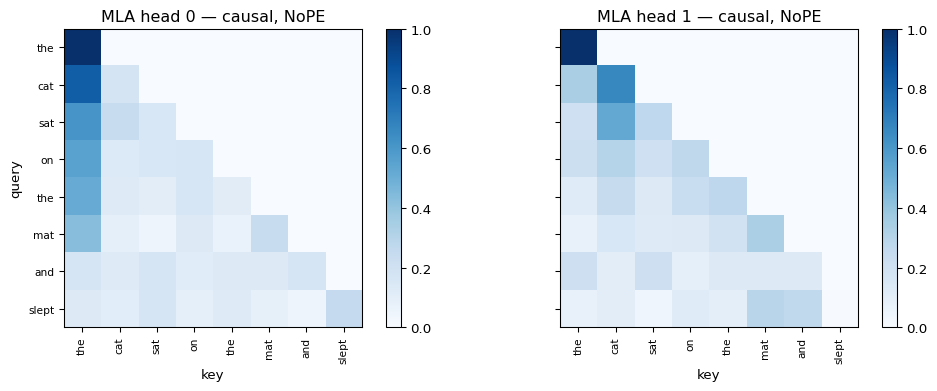

In [29]:
h = 0
I = A_["heads"][h]
print("STEP 3  scores, causal mask, softmax\n")
show_mat(I["scores"], "q k^T / sqrt(d_h)   (NaN = masked)", rows=rowlab, cols=rowlab, prec=3)
print()
show_mat(I["P"], "softmax over the unmasked entries", rows=rowlab, cols=rowlab, prec=3)
print()
t = 3
s_row = I["Q"][t] @ I["K"][:t+1].T / np.sqrt(D_H)
print(f"hand check, query = token {t} '{tokens[t]}', attends to {t+1} positions:")
print(f"  q            = {np.round(I['Q'][t], 4)}")
print(f"  raw scores   = {np.round(s_row, 6)}")
print(f"  exp(s - max) = {np.round(np.exp(s_row - s_row.max()), 6)}")
print(f"  denominator  = {np.exp(s_row - s_row.max()).sum():.6f}")
print(f"  softmax      = {np.round(np.exp(s_row-s_row.max())/np.exp(s_row-s_row.max()).sum(), 6)}")
print(f"  array row    = {np.round(I['P'][t, :t+1], 6)}")
check(f"softmax row {t}", np.exp(s_row-s_row.max())/np.exp(s_row-s_row.max()).sum(), I["P"][t, :t+1])
print(f"  row sums     = {np.round(I['P'].sum(1), 6)}   (all 1)")

fig, axes = plt.subplots(1, MLA_HEADS, figsize=(11, 4.2))
for hh, ax in enumerate(np.atleast_1d(axes)):
    im = ax.imshow(A_["heads"][hh]["P"], cmap="Blues", vmin=0, vmax=1)
    ax.set(title=f"MLA head {hh} — causal, NoPE", xlabel="key", ylabel="query" if hh == 0 else "")
    ax.set_xticks(range(T)); ax.set_xticklabels(tokens, rotation=90, fontsize=8)
    ax.set_yticks(range(T)); ax.set_yticklabels(tokens if hh == 0 else [], fontsize=8)
    plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()

In [30]:
print("STEP 4  concatenate heads, gate, project\n")
show_mat(A_["Ocat"], "heads concatenated", rows=rowlab,
         cols=[f"h{hh}d{j}" for hh in range(MLA_HEADS) for j in range(D_H)])
print()
show_mat(A_["gate"], "sigma(W_g x)", rows=rowlab,
         cols=[f"h{hh}d{j}" for hh in range(MLA_HEADS) for j in range(D_H)])
print()
show_matmul(A_["gate"] * A_["Ocat"], mla_demo.Wo, Y_mla, "gated (8,8)", "W_o (8,8)",
            "MLA output (8,8)", i=0, j=0, rows_A=rowlab)

print("\n" + "=" * 78)
print("  WHAT EACH MECHANISM STORES BETWEEN TOKENS")
print("=" * 78)
kda_state = KDA_HEADS * D_K * D_V
mla_cache = D_C
full_kv   = 2 * MLA_HEADS * D_H
print(f"{'mechanism':<28} {'per token':>12} {'at T=8':>10} {'at T=1e6':>14}")
print("-" * 68)
print(f"{'KDA recurrent state':<28} {'0 (fixed)':>12} {kda_state:>10} {kda_state:>14}")
print(f"{'MLA latent cache c':<28} {mla_cache:>12} {mla_cache*T:>10} {mla_cache*1000000:>14}")
print(f"{'full K,V (what MLA avoids)':<28} {full_kv:>12} {full_kv*T:>10} {full_kv*1000000:>14}")
print("-" * 68)
print(f"MLA compression ratio: {full_kv/mla_cache:.1f}x   (K3: 2*128*... -> d_c, far larger)")
print(f"And only 1 layer in 4 pays even that. The other 3 are constant in T.")

STEP 4  concatenate heads, gate, project

heads concatenated  (8, 8)
               h0d0       h0d1       h0d2       h0d3       h1d0       h1d1       h1d2       h1d3
    0:the   +0.0050    +0.2369    +0.4749    -0.4853    -0.1908    +0.4247    +0.2952    -0.1233
    1:cat   -0.0104    +0.3700    +0.5414    -0.6320    +0.1431    +1.1545    +0.0963    -0.4165
    2:sat   +0.0155    +0.4728    +0.5751    -0.7426    +0.2417    +1.1950    +0.0700    -0.4886
     3:on   -0.0072    +0.5168    +0.5841    -0.7794    +0.2278    +1.1899    +0.0407    -0.4569
    4:the   -0.0152    +0.5668    +0.6302    -0.8462    +0.2429    +1.3390    +0.0683    -0.5106
    5:mat   -0.0101    +0.6016    +0.8453    -1.0188    +0.0082    +1.4159    +0.2929    -0.5357
    6:and   -0.0356    +0.5901    +0.7871    -0.9785    -0.0233    +1.0252    +0.2093    -0.3842
  7:slept   +0.0765    +0.4648    +0.2577    -0.5685    -0.2440    +1.0366    +0.2905    -0.3280

sigma(W_g x)  (8, 8)
               h0d0       h0d1      

---
# 11. Assembling the full stack

Everything above was a component in isolation. Now the wiring, exactly as in the architecture diagram:

```
group_sum = 0
for each sublayer i in block n:
      h  = AttnRes_read( w_i , [ b0 , b1 ... b_{n-1} ] + [ group_sum if i >= 2 ] )
      y  = Module( RMSNorm(h) )                    # KDA / MLA / MoE
      group_sum = group_sum + y                    # the "+" node in the diagram
b_n = group_sum                                    # block summary
```

Three things this makes explicit:

**Pre-norm.** RMSNorm sits *inside* the sublayer, between the AttnRes read and the module. The thing added to the group sum is the raw module output. This is `x + Sublayer(RMSNorm(x))` restructured so that the `x` is itself chosen by attention.

**The `+` node is the group sum, not a classical residual.** In a standard Transformer the residual and the layer input are the same object. Here they are different: the group sum $b_n^i$ accumulates, while the layer *input* is a fresh attention read over $[b_0, \dots, b_{n-1}, b_n^i]$. The read can recover the classical residual by putting all its mass on $b_n^i$ — and §12 shows how much mass it actually puts there.

**Layer 1 is dense.** Table 1 of the report lists `Number of Dense Layers = 1`: the FFN of layer 1 is an ordinary SiTU-GLU feed-forward at full width; layers 2–93 are LatentMoE. A common choice — the first layer's token distribution is close to the raw embedding distribution and routes poorly.

In [31]:
class DenseFFN:
    def __init__(self, seed):
        r = np.random.default_rng(seed)
        self.Wg = xavier(D_MODEL, D_FF_DENSE, r)
        self.Wu = xavier(D_MODEL, D_FF_DENSE, r)
        self.Wd = xavier(D_FF_DENSE, D_MODEL, r)
    def forward(self, X):
        return situ_glu(X, self.Wg, self.Wu) @ self.Wd, {}


class KimiK3:
    def __init__(self, seed=1234):
        r = np.random.default_rng(seed)
        self.attn, self.ffn = [], []
        for li in range(N_LAYERS):
            is_mla = (li % LAYERS_PER_BLK) == LAYERS_PER_BLK - 1
            self.attn.append(GatedMLA(seed + 100 + li) if is_mla else KDA(seed + 100 + li))
            self.ffn.append(DenseFFN(seed + 200) if li == 0 else LatentMoE(seed + 200 + li))
        # one pseudo-query per SUBLAYER, plus one for the final block read
        self.w = [r.normal(0, 1.0, D_MODEL) for _ in range(2 * N_LAYERS)]
        self.w_final = r.normal(0, 1.0, D_MODEL)
        self.kinds = ["MLA" if (li % LAYERS_PER_BLK) == LAYERS_PER_BLK - 1 else "KDA"
                      for li in range(N_LAYERS)]

    def forward(self, X0, trace=False):
        b0 = X0
        blocks, rec = [], []
        for nb in range(N_BLOCKS):
            gs = np.zeros_like(X0)
            for li_in in range(LAYERS_PER_BLK):
                li = nb * LAYERS_PER_BLK + li_in
                for kind in ("attn", "ffn"):
                    si = 2 * li + (0 if kind == "attn" else 1)
                    i_in_block = li_in * 2 + (0 if kind == "attn" else 1)
                    srcs = [b0] + blocks
                    names = ["b0"] + [f"b{j+1}" for j in range(len(blocks))]
                    if i_in_block >= 1:
                        srcs, names = srcs + [gs.copy()], names + [f"b{nb+1}^{i_in_block}"]
                    h, A = attnres_read(self.w[si], srcs)
                    hn = rmsnorm(h)
                    mod = self.attn[li] if kind == "attn" else self.ffn[li]
                    if kind == "attn":
                        y, info = (kda_forward(mod, hn) if isinstance(mod, KDA)
                                   else mod.forward(hn))
                    else:
                        y, info = mod.forward(hn)
                    gs = gs + y
                    if trace:
                        rec.append(dict(sub=si, block=nb + 1, layer=li + 1, kind=kind,
                                        module=("MLA" if isinstance(mod, GatedMLA) else
                                                "KDA" if isinstance(mod, KDA) else
                                                "Dense" if isinstance(mod, DenseFFN) else "MoE"),
                                        names=names, alpha=A, h=h, y=y, gs=gs.copy(), info=info))
            blocks.append(gs.copy())
        hf, Af = attnres_read(self.w_final, [b0] + blocks,
                              ["b0"] + [f"b{j+1}" for j in range(N_BLOCKS)])
        hn = rmsnorm(hf)
        logits = hn @ E.T                                     # weight tying
        return logits, dict(blocks=blocks, final_alpha=Af, h_final=hf, h_norm=hn, trace=rec)


model = KimiK3(seed=1234)
logits, R = model.forward(X0, trace=True)

print(f"{'#':>3} {'blk':>4} {'layer':>6} {'sublayer':>9} {'module':>7} | {'AttnRes sources':<26} "
      f"| {'||y||':>7} {'||group sum||':>13}")
print("-" * 100)
for t_ in R["trace"]:
    print(f"{t_['sub']+1:>3} {t_['block']:>4} {t_['layer']:>6} {t_['kind']:>9} {t_['module']:>7} | "
          f"{', '.join(t_['names']):<26} | {np.linalg.norm(t_['y']):>7.3f} "
          f"{np.linalg.norm(t_['gs']):>13.3f}")
print("-" * 100)
print(f"logits {logits.shape}   (weight-tied to the embedding table, W_out = E^T)")

  #  blk  layer  sublayer  module | AttnRes sources            |   ||y|| ||group sum||
----------------------------------------------------------------------------------------------------
  1    1      1      attn     KDA | b0                         |   4.880         4.880
  2    1      1       ffn   Dense | b0, b1^1                   |   2.184         5.515
  3    1      2      attn     KDA | b0, b1^2                   |   4.324         6.023
  4    1      2       ffn     MoE | b0, b1^3                   |   7.193         9.407
  5    1      3      attn     KDA | b0, b1^4                   |   4.787        10.591
  6    1      3       ffn     MoE | b0, b1^5                   |   8.403        13.230
  7    1      4      attn     MLA | b0, b1^6                   |   6.202        12.982
  8    1      4       ffn     MoE | b0, b1^7                   |   7.594        13.879
  9    2      5      attn     KDA | b0, b1                     |   4.358         4.358
 10    2      5       ffn    

## 11.1 What the depth attention actually reads

$\alpha$ is a real distribution over sources, and it is worth looking at. Two patterns to check for:

* If a sublayer puts nearly all its mass on the current group sum, it has reproduced a classical residual connection.
* If it puts mass on `b0`, it is reaching past every intervening layer straight back to the token embedding — the thing a summed residual stream cannot do selectively.

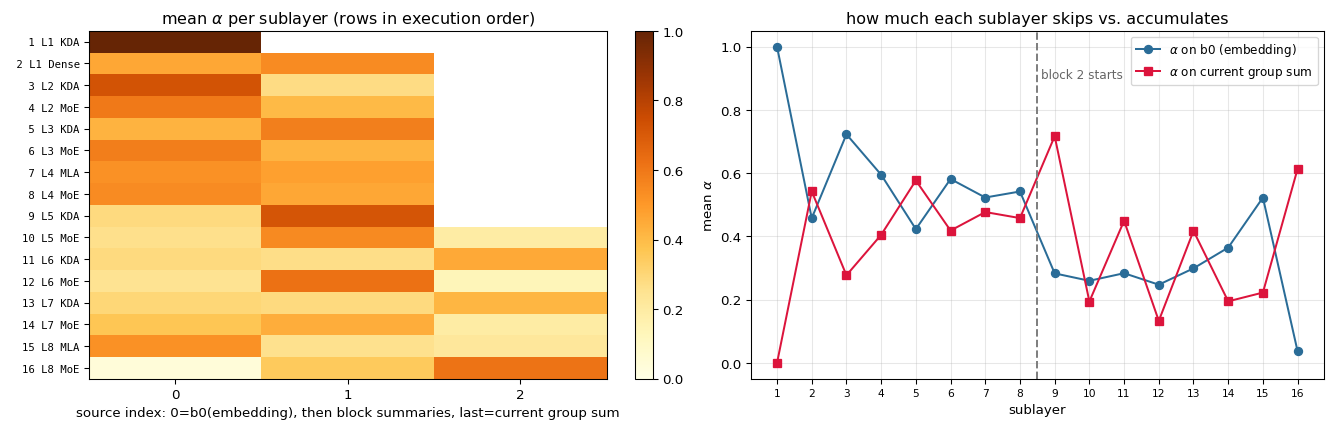

read this as: a classical residual stream would be a solid red line at 1.0.
anything below that is the model choosing to look further back than one step.


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# heatmap: mean alpha per sublayer over the available sources
maxs = max(len(t_["names"]) for t_ in R["trace"])
Aall = np.full((len(R["trace"]), maxs), np.nan)
ylab = []
for i, t_ in enumerate(R["trace"]):
    a = t_["alpha"].mean(0)
    Aall[i, :len(a)] = a
    ylab.append(f"{t_['sub']+1:>2} L{t_['layer']} {t_['module']}")
im = axes[0].imshow(Aall, cmap="YlOrBr", vmin=0, vmax=1, aspect="auto")
axes[0].set(title=r"mean $\alpha$ per sublayer (rows in execution order)",
            xlabel="source index: 0=b0(embedding), then block summaries, last=current group sum")
axes[0].set_yticks(range(len(ylab))); axes[0].set_yticklabels(ylab, fontsize=8, family="monospace")
axes[0].set_xticks(range(maxs))
plt.colorbar(im, ax=axes[0], fraction=.046)

emb_mass = [t_["alpha"].mean(0)[0] for t_ in R["trace"]]
gs_mass  = [t_["alpha"].mean(0)[-1] if len(t_["names"]) > 1 else 0 for t_ in R["trace"]]
xx = np.arange(len(R["trace"]))
axes[1].plot(xx, emb_mass, "o-", color="#2a6c97", label=r"$\alpha$ on b0 (embedding)")
axes[1].plot(xx, gs_mass, "s-", color="crimson", label=r"$\alpha$ on current group sum")
axes[1].axvline(2 * LAYERS_PER_BLK - .5, ls="--", color="0.5")
axes[1].text(2 * LAYERS_PER_BLK - .4, .9, "block 2 starts", fontsize=9, color="0.4")
axes[1].set(xlabel="sublayer", ylabel=r"mean $\alpha$", ylim=(-.05, 1.05),
            title="how much each sublayer skips vs. accumulates")
axes[1].set_xticks(xx); axes[1].set_xticklabels([f"{i+1}" for i in xx], fontsize=8)
axes[1].legend(fontsize=9); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("read this as: a classical residual stream would be a solid red line at 1.0.")
print("anything below that is the model choosing to look further back than one step.")

---
# 12. Final Block AttnRes → RMSNorm → logits

The last AttnRes read is different from all the others: its sources are the **completed block summaries** $[b_0, b_1, \dots, b_N]$, with no partial sum. This is the "Final Block AttnRes" node in the architecture diagram, and it is where the depth attention gets to weigh whole blocks against each other.

Then a final RMSNorm and a linear projection to the vocabulary. As in the Transformer notebook, the output matrix is **tied** to the embedding table, $W_{out} = E^\top$.

sources for the final read:
   0: b0 (embedding)
   1: b1 (block 1 summary)
   2: b2 (block 2 summary)

final alpha  (8, 3)
                 b0         b1         b2
    0:the   +0.9347    +0.0373    +0.0280
    1:cat   +0.0444    +0.0527    +0.9029
    2:sat   +0.0687    +0.4179    +0.5134
     3:on   +0.2503    +0.2367    +0.5129
    4:the   +0.9458    +0.0222    +0.0320
    5:mat   +0.1364    +0.3004    +0.5632
    6:and   +0.0439    +0.0443    +0.9118
  7:slept   +0.4591    +0.0291    +0.5118

aggregated h  (8, 8)
                 d0         d1         d2         d3         d4         d5         d6         d7
    0:the   -0.1556    +0.0535    -0.1102    +0.6490    -0.9138    +0.2654    +0.3940    -0.6652
    1:cat   -1.6809    -0.5936    -1.1608    -1.3958    -0.6903    -1.5513    +1.8863    -0.6001
    2:sat   +1.5543    -0.2203    -0.4328    +0.7340    +0.3178    -0.6682    +0.8691    -1.2611
     3:on   +0.7227    +0.3734    +0.3141    -0.3519    -0.1555    -2.4909    +1.4265   

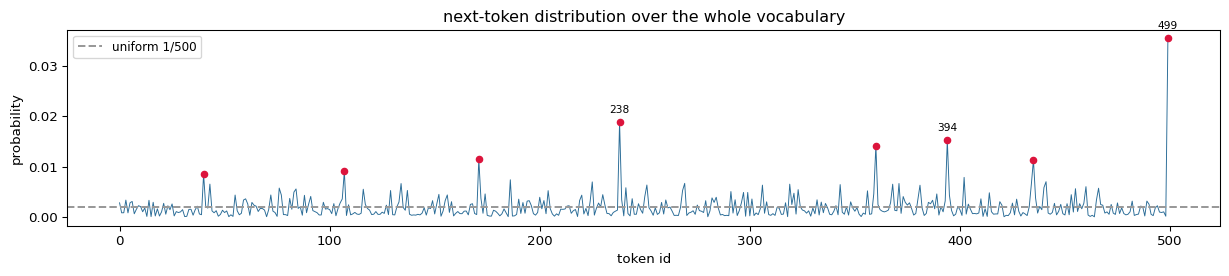

In [33]:
print("sources for the final read:")
for j, nm in enumerate(["b0 (embedding)"] + [f"b{j+1} (block {j+1} summary)" for j in range(N_BLOCKS)]):
    print(f"   {j}: {nm}")
print()
show_mat(R["final_alpha"], "final alpha", rows=rowlab,
         cols=["b0"] + [f"b{j+1}" for j in range(N_BLOCKS)])
print()
show_mat(R["h_final"], "aggregated h", rows=rowlab, cols=[f"d{j}" for j in range(D_MODEL)])
print()
show_mat(R["h_norm"], "RMSNorm(h)", rows=rowlab, cols=[f"d{j}" for j in range(D_MODEL)])
print()
print(f"logits = RMSNorm(h) @ E^T :  (8,{D_MODEL}) @ ({D_MODEL},{VOCAB_SIZE}) -> {logits.shape}")
print(f"\nhand check logits[7, {ids[0]}]  (score for the word '{tokens[0]}' after '{tokens[7]}'):")
print(f"  h    = {np.round(R['h_norm'][7], 4)}")
print(f"  E[{ids[0]}] = {np.round(E[ids[0]], 4)}")
print(f"  {expand(R['h_norm'][7], E[ids[0]])}")
print(f"  = {float(R['h_norm'][7] @ E[ids[0]]):+.6f}   array = {logits[7, ids[0]]:+.6f}")
check("logit", float(R["h_norm"][7] @ E[ids[0]]), logits[7, ids[0]])

probs = softmax(logits, axis=-1)
print(f"\nnext-token distribution after the full sentence '{sentence}':")
top = np.argsort(-probs[-1])[:8]
for rk, tid in enumerate(top):
    wname = id2word.get(int(tid), f"<id {tid}>")
    bar = "#" * int(probs[-1, tid] * 600)
    print(f"  {rk+1}. id {tid:>3} {wname:<9} p = {probs[-1, tid]:.5f}  {bar}")
print(f"\n  entropy = {-(probs[-1] * np.log(probs[-1] + 1e-12)).sum():.4f} nats"
      f"   (uniform over {VOCAB_SIZE} would be {np.log(VOCAB_SIZE):.4f})")
print("  Random weights: the distribution is near-uniform and the argmax is meaningless.")

plt.figure(figsize=(13, 3))
plt.plot(probs[-1], lw=.7, color="#2a6c97")
plt.scatter(top, probs[-1, top], color="crimson", zorder=5, s=22)
for tid in top[:3]:
    plt.annotate(id2word.get(int(tid), str(tid)), (tid, probs[-1, tid]),
                 textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
plt.axhline(1 / VOCAB_SIZE, ls="--", color="0.6", label="uniform 1/500")
plt.title("next-token distribution over the whole vocabulary")
plt.xlabel("token id"); plt.ylabel("probability"); plt.legend(fontsize=9)
plt.tight_layout(); plt.show()

---
# 13. Autoregressive decoding — and the point of the whole architecture

Everything so far ran on all 8 tokens at once. Generation runs **one token at a time**, and this is where the architecture pays off.

## What each mechanism has to do at step $t$

| | softmax attention | KDA | Gated MLA |
|---|---|---|---|
| what is stored | $K, V$ for all $t$ tokens | $S \in \mathbb{R}^{d_k\times d_v}$ | $c$ for all $t$ tokens |
| cost of step $t$ | $O(t \cdot d)$ | $O(d_k d_v)$ — **independent of $t$** | $O(t \cdot d_c)$ |
| memory growth | linear in $t$ | **none** | linear, but $d_c$ per token |

For KDA the incremental step is literally equation (1) applied once. There is no approximation: the state after the recurrent step is *bit-for-bit* the state the chunkwise kernel would produce.

One detail that is easy to forget: the **ShortConv needs the previous token's projection**, so each KDA layer also caches the previous sublayer input $x_{t-1}$ (4 or 8 numbers — negligible).

The cell below implements incremental decoding and then verifies it against the parallel forward pass of §11.

In [34]:
class Cache:
    def __init__(self, model):
        self.S    = [[np.zeros((D_K, D_V)) for _ in range(KDA_HEADS)]
                     if isinstance(m, KDA) else None for m in model.attn]
        self.xprev = [np.zeros(D_MODEL) if isinstance(m, KDA) else None for m in model.attn]
        self.c    = [[] if isinstance(m, GatedMLA) else None for m in model.attn]
        self.b0   = []          # per-token embedding
        self.blocks = [[] for _ in range(N_BLOCKS)]   # per-token block summaries


def kda_step(mod, x, xprev, S_list):
    '''One token through KDA. Updates S in place. Returns (y, new_S_list).'''
    outs, newS = [], []
    for h in range(KDA_HEADS):
        qp = x @ mod.Wq[h]; kp = x @ mod.Wk[h]; vp = x @ mod.Wv[h]
        qpp = xprev @ mod.Wq[h]; kpp = xprev @ mod.Wk[h]; vpp = xprev @ mod.Wv[h]
        qc = mod.cq[h][0] * qp + mod.cq[h][1] * qpp      # ShortConv with cached history
        kc = mod.ck[h][0] * kp + mod.ck[h][1] * kpp
        vc = mod.cv[h][0] * vp + mod.cv[h][1] * vpp
        q, k, v = l2norm(swish(qc)), l2norm(swish(kc)), swish(vc)
        beta = float(sigmoid(x @ mod.Wb[h])[0])
        z = (x @ mod.Wa_dn) @ mod.Wa_up[h] + mod.b_alpha[h]
        alpha = np.exp(G_MIN * sigmoid(np.exp(mod.A_log[h]) * z))
        S = S_list[h]
        S = (np.eye(D_K) - beta * np.outer(k, k)) @ (np.diag(alpha) @ S) + beta * np.outer(k, v)
        outs.append(rmsnorm(S.T @ q)); newS.append(S)
    gate = sigmoid(x @ mod.Wg)
    return (gate * np.concatenate(outs)) @ mod.Wo, newS


def mla_step(mod, x, c_hist):
    c = x @ mod.Wc
    c_hist = c_hist + [c]
    Cm = np.stack(c_hist)
    outs = []
    for h in range(MLA_HEADS):
        K, V = Cm @ mod.Wuk[h], Cm @ mod.Wuv[h]
        qh = x @ mod.Wq[h]
        w = softmax(qh @ K.T / np.sqrt(D_H))
        outs.append(w @ V)
    gate = sigmoid(x @ mod.Wg)
    return (gate * np.concatenate(outs)) @ mod.Wo, c_hist


def step_token(model, cache, x0):
    '''Process ONE token. x0 = its embedding (d,). Returns logits (V,).'''
    cache.b0.append(x0)
    blocks_here = []
    for nb in range(N_BLOCKS):
        gs = np.zeros(D_MODEL)
        for li_in in range(LAYERS_PER_BLK):
            li = nb * LAYERS_PER_BLK + li_in
            for kind in ("attn", "ffn"):
                si = 2 * li + (0 if kind == "attn" else 1)
                i_in_block = li_in * 2 + (0 if kind == "attn" else 1)
                srcs = [x0] + blocks_here
                if i_in_block >= 1:
                    srcs = srcs + [gs.copy()]
                V = np.stack(srcs)
                a = softmax(rmsnorm(V) @ model.w[si])
                hn = rmsnorm(a @ V)
                if kind == "attn":
                    mod = model.attn[li]
                    if isinstance(mod, KDA):
                        y, cache.S[li] = kda_step(mod, hn, cache.xprev[li], cache.S[li])
                        cache.xprev[li] = hn
                    else:
                        y, cache.c[li] = mla_step(mod, hn, cache.c[li])
                else:
                    y = model.ffn[li].forward(hn[None, :])[0][0]
                gs = gs + y
        blocks_here.append(gs.copy())
    Vf = np.stack([x0] + blocks_here)
    af = softmax(rmsnorm(Vf) @ model.w_final)
    return rmsnorm(af @ Vf) @ E.T


print("running the same 8 tokens ONE AT A TIME through the incremental path...\n")
cache = Cache(model)
inc_logits = np.stack([step_token(model, cache, X0[t]) for t in range(T)])

print(f"{'token':>10} {'max |parallel - incremental|':>32}")
print("-" * 46)
for t in range(T):
    print(f"{t}:{tokens[t]:<8} {np.abs(logits[t] - inc_logits[t]).max():>32.3e}")
print("-" * 46)
check("ALL logits: parallel vs incremental", logits, inc_logits, tol=1e-9)
print()
print("The recurrent state carries EXACTLY the information the chunkwise kernel would")
print("have computed. Nothing about decoding is an approximation of training.")
print()
for li, kind in enumerate(model.kinds):
    if kind == "KDA":
        print(f"  layer {li+1} KDA : state = {KDA_HEADS} heads x {D_K}x{D_V} "
              f"= {KDA_HEADS*D_K*D_V:>3} numbers  (independent of T)")
    else:
        print(f"  layer {li+1} MLA : cache = {len(cache.c[li])} tokens x d_c={D_C} "
              f"= {len(cache.c[li])*D_C:>3} numbers  (grows with T)")

running the same 8 tokens ONE AT A TIME through the incremental path...

     token     max |parallel - incremental|
----------------------------------------------
0:the                             3.331e-15
1:cat                             1.607e-14
2:sat                             7.883e-14
3:on                              1.554e-14
4:the                             1.255e-14
5:mat                             3.642e-14
6:and                             6.928e-14
7:slept                           1.417e-13
----------------------------------------------
  ALL logits: parallel vs incremental                        max|diff| = 1.417e-13   MATCH: True

The recurrent state carries EXACTLY the information the chunkwise kernel would
have computed. Nothing about decoding is an approximation of training.

  layer 1 KDA : state = 2 heads x 4x4 =  32 numbers  (independent of T)
  layer 2 KDA : state = 2 heads x 4x4 =  32 numbers  (independent of T)
  layer 3 KDA : state = 2 heads x 4x4 =  32 

In [35]:
def generate(model, prompt_ids, n_new=6, temperature=1.0, greedy=True, seed=0):
    rng = np.random.default_rng(seed)
    cache = Cache(model)
    out_ids = list(prompt_ids)
    lg = None
    for tid in prompt_ids:                          # prefill
        lg = step_token(model, cache, E[tid])
    for step in range(n_new):                       # decode
        pr = softmax(lg / temperature)
        nxt = int(np.argmax(pr)) if greedy else int(rng.choice(VOCAB_SIZE, p=pr))
        out_ids.append(nxt)
        lg = step_token(model, cache, E[nxt])
    return out_ids


print("greedy continuation (untrained -- the words are noise, the mechanism is not)\n")
gen = generate(model, ids, n_new=6, greedy=True)
print("  prompt    : " + " ".join(id2word.get(int(i), f"<{i}>") for i in gen[:T]))
print("  generated : " + " ".join(id2word.get(int(i), f"<{i}>") for i in gen[T:]))
print()
print("with temperature sampling, same model, three different seeds:")
for sd in [0, 1, 2]:
    g = generate(model, ids, n_new=6, greedy=False, temperature=0.9, seed=sd)
    print(f"  seed {sd}: " + " ".join(id2word.get(int(i), f"<{i}>") for i in g[T:]))
print()
print("cost accounting for the last generated token:")
print(f"  KDA layers ({sum(1 for k in model.kinds if k=='KDA')}): each did ONE {D_K}x{D_V} state")
print(f"      update -- the same work as at token 1, and the same as it would do at token 1e6")
print(f"  MLA layers ({sum(1 for k in model.kinds if k=='MLA')}): each attended over "
      f"{T+6} cached latents -- this is the only term that grows")

greedy continuation (untrained -- the words are noise, the mechanism is not)

  prompt    : the cat sat on the mat and slept
  generated : <499> the the the the the

with temperature sampling, same model, three different seeds:
  seed 0: <348> <152> <26> <14> <398> <451>
  seed 1: <279> <472> <80> <475> <162> <199>
  seed 2: <152> <135> <410> <62> <255> <373>

cost accounting for the last generated token:
  KDA layers (6): each did ONE 4x4 state
      update -- the same work as at token 1, and the same as it would do at token 1e6
  MLA layers (2): each attended over 14 cached latents -- this is the only term that grows


---
# 14. Summary — every shape, and what changes at 2.8T

In [36]:
print("=" * 84)
print("  SHAPES, END TO END")
print("=" * 84)
rows = [
    ("token ids",                  f"({T},)",                          "8 integers"),
    ("embedding X0 = E[ids]",      f"({T}, {D_MODEL})",                "no PE added"),
    ("--- per sublayer ---", "", ""),
    ("AttnRes sources",            f"n_src x ({T}, {D_MODEL})",        "n_src <= 1 + N_blocks + 1"),
    ("AttnRes alpha",              f"({T}, n_src)",                    "softmax over DEPTH"),
    ("sublayer input h",           f"({T}, {D_MODEL})",                "weighted sum of sources"),
    ("RMSNorm(h)",                 f"({T}, {D_MODEL})",                "pre-norm"),
    ("--- KDA ---", "", ""),
    ("Q, K per head",              f"({T}, {D_K})",                    "L2-normalised"),
    ("V per head",                 f"({T}, {D_V})",                    "not normalised"),
    ("alpha (decay)",              f"({T}, {D_K})",                    "channel-wise, in (e^-5, 1)"),
    ("beta",                       f"({T},)",                          "scalar per token"),
    ("state S",                    f"({D_K}, {D_V})",                  "CONSTANT in T"),
    ("Gamma per chunk",            f"({CHUNK}, {D_K})",                "cumprod of alpha"),
    ("A per chunk",                f"({CHUNK}, {CHUNK})",              "Tril, diagonal kept"),
    ("--- Gated MLA ---", "", ""),
    ("latent c",                   f"({T}, {D_C})",                    "the entire KV cache"),
    ("K, V rebuilt per head",      f"({T}, {D_H})",                    "never cached"),
    ("attention probs",            f"({T}, {T})",                      "causal, NoPE"),
    ("--- LatentMoE ---", "", ""),
    ("router s",                   f"({T}, {N_ROUTED})",               "sigmoid, not softmax"),
    ("top-k indices",              f"({T}, {K_TOP})",                  "from s + b"),
    ("cutoff alpha_i",             f"({T},)",                          "the (k+1)-th entry"),
    ("latent z",                   f"({T}, {ELL})",                    "ell = d/2"),
    ("routed aggregate u",         f"({T}, {ELL})",                    "then RMSNorm"),
    ("--- output ---", "", ""),
    ("block summaries",            f"{N_BLOCKS} x ({T}, {D_MODEL})",   "b_1 ... b_N"),
    ("logits",                     f"({T}, {VOCAB_SIZE})",             "W_out = E^T"),
]
for a, b, c in rows:
    if a.startswith("---"):
        print(f"\n{a}")
    else:
        print(f"  {a:<26} {b:>22}   {c}")

print("\n" + "=" * 84)
print("  PARAMETER COUNT OF THIS TOY")
print("=" * 84)
def nparams(o):
    tot = 0
    for v in vars(o).values():
        if isinstance(v, np.ndarray): tot += v.size
        elif isinstance(v, list):
            for w_ in v:
                if isinstance(w_, np.ndarray): tot += w_.size
    return tot
tot_attn = sum(nparams(m) for m in model.attn)
tot_ffn  = sum(nparams(m) for m in model.ffn)
tot_w    = sum(v.size for v in model.w) + model.w_final.size
print(f"  attention layers  {tot_attn:>8}")
print(f"  FFN / MoE layers  {tot_ffn:>8}   ({tot_ffn/(tot_attn+tot_ffn)*100:.0f}% of the backbone)")
print(f"  AttnRes queries   {tot_w:>8}   ({2*N_LAYERS+1} vectors of {D_MODEL})")
print(f"  embedding (tied)  {E.size:>8}")
print(f"  {'TOTAL':<17} {tot_attn+tot_ffn+tot_w+E.size:>8}")
print(f"\n  activated per token: only {K_TOP} of {N_ROUTED} routed experts run in each MoE layer.")

  SHAPES, END TO END
  token ids                                    (8,)   8 integers
  embedding X0 = E[ids]                      (8, 8)   no PE added

--- per sublayer ---
  AttnRes sources                    n_src x (8, 8)   n_src <= 1 + N_blocks + 1
  AttnRes alpha                          (8, n_src)   softmax over DEPTH
  sublayer input h                           (8, 8)   weighted sum of sources
  RMSNorm(h)                                 (8, 8)   pre-norm

--- KDA ---
  Q, K per head                              (8, 4)   L2-normalised
  V per head                                 (8, 4)   not normalised
  alpha (decay)                              (8, 4)   channel-wise, in (e^-5, 1)
  beta                                         (8,)   scalar per token
  state S                                    (4, 4)   CONSTANT in T
  Gamma per chunk                            (4, 4)   cumprod of alpha
  A per chunk                                (4, 4)   Tril, diagonal kept

--- Gated MLA --

## What changes at the real scale

Nothing structural. Every formula above is the formula in the report. These are the numbers that grow, and the systems work each one forces:

| component | here | Kimi K3 | what it forces |
|---|---|---|---|
| KDA state per head | $4\times4$ | $d_k \times d_v$, fixed | the state is cheap to transfer → KDA Context Parallelism, and prefix-cache checkpoints |
| chunk serialism | 2 chunks | millions of tokens | **FlashKDA**: a CUTLASS chunkwise kernel that overlaps intra-chunk matmul with cross-chunk state propagation |
| cross-device recurrence | n/a | $P$ ranks | **KCP**: because $S_t = M_t S_{t-1} + \beta_t k_t v_t^\top$ is affine, each segment decomposes into a cumulative transition $M$ and a from-zero state $\tilde S$, both locally computable, then combined by prefix scan with one fixed-size all-gather |
| routed experts | 8 | 896 | **MoonEP**: perfect load balance with at most $E/R$ redundant experts per rank — proved, and proved tight |
| active per token | 2 | 16 | the latent $\ell = d/2$ keeps all-to-all traffic flat as $k$ grows |
| AttnRes sources | ≤ 3 | ≤ 9 | cache-based pipeline communication; only newly generated blocks cross PP stages |
| layers | 8 | 93 | PP with virtual stages + ZeRO-1 DP + Pipeline ZeRO-2 gradient sharding to CPU |
| context | 8 | 1M | 8K→64K in pre-training, 256K→1M in cooldown; NoPE means nothing to rescale |
| precision | float64 | MXFP4 weights / MXFP8 activations | QAT through all of SFT and RL, so rollout and training share one quantisation scheme |

## What is deliberately left out of this notebook

* **MoonViT-V2**, the from-scratch vision tower. Its tokens would simply appear as extra rows in `X0` — the backbone is unchanged, which is the entire point of "native multimodal".
* **Multi-token prediction / EAGLE-3 draft model.** One detail is worth stating anyway: the draft fuses low-, mid- and high-level features through $W_{E3}$ initialised as $[\,0\;\;0\;\;I\,]$, so at step zero the fused representation *is* the high-level feature the MTP layer was pre-trained on. And it optimises $-\log\sum_x \min(p(x), q(x))$ — the acceptance rate itself — rather than KL, since minimising KL does not maximise acceptance for a capacity-limited draft.
* **Training**: Muon (per-head), the RL pipeline, multi-teacher on-policy distillation.

---
# APPENDIX — every number, by hand

Two traces, in the style of the Transformer notebook's appendix. Nothing here calls a helper that hides arithmetic: every sum is written out.

## TRACE A — token 4 (`"the"`, the second occurrence) through block 1, layer 1

### A.1 The embedding, and the problem NoPE creates

In [37]:
tA = 4
print(f"token {tA} = '{tokens[tA]}', id = {ids[tA]}")
print(f"  X0[{tA}] = E[{ids[tA]}] = {np.round(X0[tA], 6)}")
print(f"  X0[0]  = E[{ids[0]}] = {np.round(X0[0], 6)}")
print(f"  equal? {np.allclose(X0[0], X0[tA])}")
print()
print("  No positional encoding is added. At the input these two tokens are")
print("  indistinguishable. A2-A6 show where they diverge.")

token 4 = 'the', id = 83
  X0[4] = E[83] = [-0.252  0.038 -0.09   0.532 -0.937  0.386  0.441 -0.733]
  X0[0]  = E[83] = [-0.252  0.038 -0.09   0.532 -0.937  0.386  0.441 -0.733]
  equal? True

  No positional encoding is added. At the input these two tokens are
  indistinguishable. A2-A6 show where they diverge.


### A.2 The AttnRes read for sublayer 1

Block 1, sublayer 1 is the *first* sublayer of the *first* block, so its only source is $b_0$ — the embedding. With one source the softmax is degenerate: $\alpha = 1$, and $h = b_0$.

This is worth seeing explicitly, because it shows the mechanism reduces correctly to "just take the input" when there is nothing to choose between.

In [38]:
tr0 = R["trace"][0]
print(f"  sources        : {tr0['names']}")
print(f"  alpha[{tA}]      : {np.round(tr0['alpha'][tA], 6)}   (one source -> softmax of a single logit = 1)")
print(f"  h[{tA}]          : {np.round(tr0['h'][tA], 6)}")
check("h == embedding", tr0["h"][tA], X0[tA])
hn = rmsnorm(tr0["h"])
print()
r_ = tr0["h"][tA]
print("  RMSNorm, written out:")
print(f"    x        = {np.round(r_, 6)}")
print(f"    sum x^2  = {' + '.join(f'{v:.4f}^2' for v in r_)}")
print(f"             = {np.sum(r_**2):.8f}")
print(f"    mean     = {np.sum(r_**2)/D_MODEL:.8f}")
print(f"    rms      = {np.sqrt(np.sum(r_**2)/D_MODEL + 1e-6):.8f}")
print(f"    x / rms  = {np.round(r_/np.sqrt(np.sum(r_**2)/D_MODEL + 1e-6), 6)}")
check("RMSNorm(h)", r_/np.sqrt(np.sum(r_**2)/D_MODEL + 1e-6), hn[tA])

  sources        : ['b0']
  alpha[4]      : [1.]   (one source -> softmax of a single logit = 1)
  h[4]          : [-0.252  0.038 -0.09   0.532 -0.937  0.386  0.441 -0.733]
  h == embedding                                             max|diff| = 0.000e+00   MATCH: True

  RMSNorm, written out:
    x        = [-0.252  0.038 -0.09   0.532 -0.937  0.386  0.441 -0.733]
    sum x^2  = -0.2520^2 + 0.0376^2 + -0.0901^2 + 0.5317^2 + -0.9373^2 + 0.3859^2 + 0.4406^2 + -0.7331^2
             = 2.11464854
    mean     = 0.26433107
    rms      = 0.51413234
    x / rms  = [-0.49   0.073 -0.175  1.034 -1.823  0.751  0.857 -1.426]
  RMSNorm(h)                                                 max|diff| = 0.000e+00   MATCH: True


### A.3 KDA head 0 — the projections for this token

In [39]:
kmod = model.attn[0]
Xin  = rmsnorm(tr0["h"])
P0   = kmod.head_inputs(Xin, 0)

print(f"q_proj[{tA}] = X[{tA}] @ Wq   -- one dot product per output channel")
for j in range(D_K):
    print(f"  channel k{j}: {expand(Xin[tA], kmod.Wq[0][:, j])}")
    print(f"      = {float(Xin[tA] @ kmod.Wq[0][:, j]):+.6f}   array = {P0['q_proj'][tA, j]:+.6f}")
print()
print(f"ShortConv (needs token {tA-1} = '{tokens[tA-1]}'):")
c0, c1 = kmod.cq[0][0], kmod.cq[0][1]
print(f"  c0 = {np.round(c0, 4)}   c1 = {np.round(c1, 4)}   (per-channel)")
for j in range(D_K):
    val = c0[j] * P0["q_proj"][tA, j] + c1[j] * P0["q_proj"][tA-1, j]
    print(f"  k{j}: {c0[j]:+.4f}*{P0['q_proj'][tA,j]:+.4f} + {c1[j]:+.4f}*{P0['q_proj'][tA-1,j]:+.4f}"
          f" = {val:+.6f}   array = {P0['q_conv'][tA,j]:+.6f}")
print()
print("  <-- HERE is the first place the two copies of 'the' differ: position 0 had")
print(f"      no predecessor, position {tA} convolves with '{tokens[tA-1]}'.")
print(f"      q_conv[0] = {np.round(P0['q_conv'][0], 5)}")
print(f"      q_conv[{tA}] = {np.round(P0['q_conv'][tA], 5)}")
print()
print("Swish then L2Norm:")
sw_ = swish(P0["q_conv"][tA])
print(f"  swish   = {np.round(sw_, 6)}")
print(f"  ||.||   = sqrt({' + '.join(f'{v:.4f}^2' for v in sw_)}) = {np.linalg.norm(sw_):.6f}")
print(f"  q       = {np.round(sw_/np.linalg.norm(sw_), 6)}")
check("Q", sw_/np.linalg.norm(sw_), P0["Q"][tA])

q_proj[4] = X[4] @ Wq   -- one dot product per output channel
  channel k0: (-0.4902)*(+0.6712) + (+0.0732)*(+0.1125) + (-0.1753)*(+0.4054) + (+1.0343)*(-0.3265) + 
      (-1.8230)*(-0.2550) + (+0.7506)*(-0.0963) + (+0.8569)*(-0.1597) + (-1.4258)*(-0.6700)
      = +0.481397   array = +0.481397
  channel k1: (-0.4902)*(-0.6141) + (+0.0732)*(-0.3356) + (-0.1753)*(+0.1125) + (+1.0343)*(-0.4001) + 
      (-1.8230)*(-0.3414) + (+0.7506)*(+0.4080) + (+0.8569)*(+0.3194) + (-1.4258)*(+0.0811)
      = +0.929692   array = +0.929692
  channel k2: (-0.4902)*(-0.0312) + (+0.0732)*(-0.7061) + (-0.1753)*(-0.1986) + (+1.0343)*(+0.3615) + 
      (-1.8230)*(-0.3966) + (+0.7506)*(+0.4383) + (+0.8569)*(-0.5403) + (-1.4258)*(+0.2122)
      = +0.658812   array = +0.658812
  channel k3: (-0.4902)*(+0.2992) + (+0.0732)*(+0.5459) + (-0.1753)*(+0.6857) + (+1.0343)*(+0.0334) + 
      (-1.8230)*(+0.3816) + (+0.7506)*(+0.0529) + (+0.8569)*(-0.2665) + (-1.4258)*(-0.1980)
      = -0.794459   array = -0.794459

Short

### A.4 The decay and write gates for this token

In [40]:
zl = Xin[tA] @ kmod.Wa_dn
z_ = zl @ kmod.Wa_up[0] + kmod.b_alpha[0]
print(f"  W_down x      = {np.round(zl, 6)}   (rank-2 bottleneck)")
print(f"  W_up (.)      = {np.round(zl @ kmod.Wa_up[0], 6)}")
print(f"  + b_alpha     = {np.round(kmod.b_alpha[0], 4)}")
print(f"  z             = {np.round(z_, 6)}")
print()
for j in range(D_K):
    s_ = sigmoid(np.exp(kmod.A_log[0]) * z_[j])
    g_ = G_MIN * s_
    print(f"  k{j}: sigma(e^0 * {z_[j]:+.4f}) = {s_:.6f}  ->  g = -5*{s_:.6f} = {g_:+.6f}"
          f"  ->  alpha = e^{g_:+.4f} = {np.exp(g_):.6f}")
check("alpha", np.exp(G_MIN*sigmoid(z_)), P0["alpha"][tA])
print()
bpre = float((Xin[tA] @ kmod.Wb[0])[0])
print(f"  beta: W_b.x = {bpre:+.6f}  ->  sigmoid = 1/(1+e^{-bpre:+.6f}) = {sigmoid(bpre):.6f}")
check("beta", sigmoid(bpre), P0["beta"][tA])

  W_down x      = [ 0.054 -1.276]   (rank-2 bottleneck)
  W_up (.)      = [ 0.932  0.731  0.322 -0.76 ]
  + b_alpha     = [-1.64  -2.39  -2.929 -2.164]
  z             = [-0.708 -1.659 -2.608 -2.923]

  k0: sigma(e^0 * -0.7077) = 0.330114  ->  g = -5*0.330114 = -1.650570  ->  alpha = e^-1.6506 = 0.191941
  k1: sigma(e^0 * -1.6592) = 0.159873  ->  g = -5*0.159873 = -0.799363  ->  alpha = e^-0.7994 = 0.449615
  k2: sigma(e^0 * -2.6075) = 0.068656  ->  g = -5*0.068656 = -0.343281  ->  alpha = e^-0.3433 = 0.709439
  k3: sigma(e^0 * -2.9232) = 0.051020  ->  g = -5*0.051020 = -0.255098  ->  alpha = e^-0.2551 = 0.774841
  alpha                                                      max|diff| = 2.776e-17   MATCH: True

  beta: W_b.x = +0.150727  ->  sigmoid = 1/(1+e^-0.150727) = 0.537611
  beta                                                       max|diff| = 0.000e+00   MATCH: True


### A.5 The state update at $t = 4$, entry by entry

In [41]:
O_ref, S_all = kda_recurrent(P0)
S_prev = S_all[tA-1]
a_, b_, k_, v_, q_ = P0["alpha"][tA], P0["beta"][tA], P0["K"][tA], P0["V"][tA], P0["Q"][tA]

print("(1) DECAY  Diag(alpha) @ S_{t-1}   -- row j of S scaled by alpha_j")
show_state(S_prev, "  S_3")
print()
Sd = np.diag(a_) @ S_prev
for i_ in range(D_K):
    print(f"  row k{i_}: {a_[i_]:.6f} * {np.round(S_prev[i_],5)} = {np.round(Sd[i_],6)}")
print()
print(f"(2) ERASE  P = I - beta k k^T,  beta = {b_:.6f},  k = {np.round(k_,5)}")
Pm = np.eye(D_K) - b_ * np.outer(k_, k_)
show_state(Pm, "  P", vl=[f"k{j}" for j in range(D_K)])
print(f"  hand check P[0,1] = 0 - {b_:.6f}*{k_[0]:+.6f}*{k_[1]:+.6f} = "
      f"{-b_*k_[0]*k_[1]:+.8f}   array = {Pm[0,1]:+.8f}")
Se = Pm @ Sd
print()
show_state(Se, "  P @ decayed")
print(f"  hand check [0,0] = {expand(Pm[0], Sd[:,0])}")
print(f"       = {float(Pm[0] @ Sd[:,0]):+.8f}   array = {Se[0,0]:+.8f}")
print()
print(f"(3) WRITE  + beta * k v^T,  v = {np.round(v_,5)}")
Wr = b_ * np.outer(k_, v_)
show_state(Wr, "  beta k v^T")
print(f"  hand check [1,2] = {b_:.6f} * {k_[1]:+.6f} * {v_[2]:+.6f} = {b_*k_[1]*v_[2]:+.8f}"
      f"   array = {Wr[1,2]:+.8f}")
S_new = Se + Wr
print()
show_state(S_new, f"  ==> S_{tA}")
check(f"S_{tA}", S_new, S_all[tA])
print()
print(f"(4) READ  o = S^T q,  q = {np.round(q_,5)}")
for j in range(D_V):
    print(f"  v{j}: {expand(S_new[:,j], q_)}")
    print(f"      = {float(S_new[:,j] @ q_):+.8f}   array = {O_ref[tA,j]:+.8f}")
print()
print(f"  o[0] = {np.round(O_ref[0],6)}")
print(f"  o[{tA}] = {np.round(O_ref[tA],6)}")
print(f"  the two copies of 'the' now produce different outputs: "
      f"{not np.allclose(O_ref[0], O_ref[tA])}")

(1) DECAY  Diag(alpha) @ S_{t-1}   -- row j of S scaled by alpha_j
  S_3  (4, 4)
                 v0         v1         v2         v3
       k0   +0.0010    -0.0246    -0.0006    -0.0577
       k1   -0.0065    -0.0344    +0.0066    +0.0026
       k2   -0.2142    +0.0549    -0.1868    +0.3792
       k3   -0.0280    -0.0483    -0.0041    -0.0137

  row k0: 0.191941 * [ 0.001 -0.025 -0.001 -0.058] = [ 0.    -0.005 -0.    -0.011]
  row k1: 0.449615 * [-0.007 -0.034  0.007  0.003] = [-0.003 -0.015  0.003  0.001]
  row k2: 0.709439 * [-0.214  0.055 -0.187  0.379] = [-0.152  0.039 -0.133  0.269]
  row k3: 0.774841 * [-0.028 -0.048 -0.004 -0.014] = [-0.022 -0.037 -0.003 -0.011]

(2) ERASE  P = I - beta k k^T,  beta = 0.537611,  k = [-0.196  0.077 -0.195  0.958]
  P  (4, 4)
                 k0         k1         k2         k3
       k0   +0.9794    +0.0081    -0.0205    +0.1008
       k1   +0.0081    +0.9968    +0.0080    -0.0395
       k2   -0.0205    +0.0080    +0.9796    +0.1003
       k3   

## TRACE B — token 7 (`"slept"`) → the next-token probability

### B.1 Which experts this token was routed to, and why

In [42]:
tB = T - 1
moe_tr = [t_ for t_ in R["trace"] if t_["module"] == "MoE"][0]
info = moe_tr["info"]
print(f"first MoE sublayer (sublayer {moe_tr['sub']+1}, layer {moe_tr['layer']})\n")
print(f"  router scores for token {tB} ('{tokens[tB]}'):")
for j in range(N_ROUTED):
    sel = "  <== SELECTED" if j in info["topk"][tB] else ""
    cut = "  (cutoff)" if np.isclose(info["s"][tB, j] + 0.0, info["cutoff"][tB]) else ""
    print(f"    E{j}: s = {info['s'][tB,j]:.6f}{cut}{sel}")
print(f"\n  cutoff alpha_i (the (k+1)-th biased score) = {info['cutoff'][tB]:.6f}")
sel = info["topk"][tB]
print(f"\n  p normalisation over the {K_TOP} selected experts only:")
print(f"    s[E{sel[0]}] + s[E{sel[1]}] = {info['s'][tB,sel[0]]:.6f} + {info['s'][tB,sel[1]]:.6f}"
      f" = {info['s'][tB,sel].sum():.6f}")
for j in sel:
    print(f"    p[E{j}] = {info['s'][tB,j]:.6f} / {info['s'][tB,sel].sum():.6f} = {info['p'][tB,j]:.6f}")
print(f"    sum p  = {info['p'][tB].sum():.6f}")
print(f"\n  note the other {N_ROUTED-K_TOP} experts contribute exactly 0 -- that is the sparsity.")

first MoE sublayer (sublayer 4, layer 2)

  router scores for token 7 ('slept'):
    E0: s = 0.309197
    E1: s = 0.288658
    E2: s = 0.334596
    E3: s = 0.728520  <== SELECTED
    E4: s = 0.847728  <== SELECTED
    E5: s = 0.596475  (cutoff)
    E6: s = 0.228453
    E7: s = 0.110529

  cutoff alpha_i (the (k+1)-th biased score) = 0.596475

  p normalisation over the 2 selected experts only:
    s[E4] + s[E3] = 0.847728 + 0.728520 = 1.576247
    p[E4] = 0.847728 / 1.576247 = 0.537814
    p[E3] = 0.728520 / 1.576247 = 0.462186
    sum p  = 1.000000

  note the other 6 experts contribute exactly 0 -- that is the sparsity.


### B.2 From the block summaries to a logit

In [43]:
print(f"block summaries at token {tB}:")
for j, b_ in enumerate(R["blocks"]):
    print(f"  b{j+1} = {np.round(b_[tB], 5)}   ||.|| = {np.linalg.norm(b_[tB]):.5f}")
print(f"  b0 = {np.round(X0[tB], 5)}   ||.|| = {np.linalg.norm(X0[tB]):.5f}  (embedding)")
print()
Vf = np.stack([X0[tB]] + [b_[tB] for b_ in R["blocks"]])
Kf = rmsnorm(Vf)
lgf = Kf @ model.w_final
print(f"  w_final          = {np.round(model.w_final, 4)}")
print(f"  RMSNorm'd keys   :")
for j, nm in enumerate(["b0"] + [f"b{j+1}" for j in range(N_BLOCKS)]):
    print(f"    {nm}: {np.round(Kf[j], 5)}")
print(f"  logits           = {np.round(lgf, 6)}")
print(f"  exp(l - max)     = {np.round(np.exp(lgf - lgf.max()), 6)}")
print(f"  sum              = {np.exp(lgf - lgf.max()).sum():.6f}")
af = np.exp(lgf - lgf.max()) / np.exp(lgf - lgf.max()).sum()
print(f"  alpha            = {np.round(af, 6)}")
check("final alpha", af, R["final_alpha"][tB])
hf = af @ Vf
print(f"\n  h = alpha . V    = {np.round(hf, 6)}")
check("h_final", hf, R["h_final"][tB])
hnf = rmsnorm(hf)
print(f"  RMSNorm(h)       = {np.round(hnf, 6)}")
print()
tgt = ids[1]
print(f"  logit for token id {tgt} ('{id2word[tgt]}'):")
print(f"    {expand(hnf, E[tgt])}")
print(f"    = {float(hnf @ E[tgt]):+.8f}   array = {logits[tB, tgt]:+.8f}")
check("logit", float(hnf @ E[tgt]), logits[tB, tgt])

block summaries at token 7:
  b1 = [-1.419 -0.009  0.489 -3.448  0.681 -0.426  2.581 -0.114]   ||.|| = 4.63272
  b2 = [-0.833 -0.475 -1.156  0.216 -1.616 -1.157  1.748  0.619]   ||.|| = 3.11290
  b0 = [ 0.297  0.073 -0.457 -0.188 -0.215 -0.027  0.151  0.148]   ||.|| = 0.65528  (embedding)

  w_final          = [-0.05   0.326 -0.548 -0.27  -1.673  0.083  0.19  -0.308]
  RMSNorm'd keys   :
    b0: [ 1.283  0.317 -1.973 -0.812 -0.927 -0.118  0.65   0.638]
    b1: [-0.866 -0.006  0.298 -2.105  0.416 -0.26   1.576 -0.069]
    b2: [-0.757 -0.432 -1.051  0.196 -1.468 -1.051  1.588  0.563]
  logits           = [2.808 0.05  2.917]
  exp(l - max)     = [0.897 0.057 1.   ]
  sum              = 1.953889
  alpha            = [0.459 0.029 0.512]
  final alpha                                                max|diff| = 0.000e+00   MATCH: True

  h = alpha . V    = [-0.331 -0.21  -0.787 -0.076 -0.906 -0.617  1.039  0.382]
  h_final                                                    max|diff| = 0.000e+0

### B.3 The softmax over 500 tokens — where the denominator comes from

In [44]:
lg = logits[tB]
mx = lg.max()
print(f"  max logit        = {mx:+.6f} at id {int(np.argmax(lg))} ('{id2word.get(int(np.argmax(lg)), '?')}')")
print(f"  min logit        = {lg.min():+.6f}")
print(f"  subtracting the max keeps exp() in range: exp({lg.min()-mx:+.4f}) = {np.exp(lg.min()-mx):.3e}")
Z = np.exp(lg - mx).sum()
print(f"  Z = sum exp(l - max) over all {VOCAB_SIZE} tokens = {Z:.6f}")
print(f"  log Z + max      = {np.log(Z) + mx:.6f}   (the log-partition function)")
print()
print(f"  {'id':>5} {'word':<9} {'logit':>10} {'exp(l-max)':>12} {'p':>10}")
print("  " + "-" * 50)
for tid in np.argsort(-lg)[:6]:
    print(f"  {tid:>5} {id2word.get(int(tid),'-'):<9} {lg[tid]:>10.5f} "
          f"{np.exp(lg[tid]-mx):>12.6f} {np.exp(lg[tid]-mx)/Z:>10.6f}")
print("  " + "-" * 50)
print(f"  sum of ALL {VOCAB_SIZE} probabilities = {(np.exp(lg-mx)/Z).sum():.10f}")
check("softmax", np.exp(lg-mx)/Z, probs[tB])
print()
lab = ids[1]
print(f"  cross-entropy if the true next token were id {lab} ('{id2word[lab]}'):")
print(f"    loss = -log p = -log({probs[tB,lab]:.8f}) = {-np.log(probs[tB,lab]):.6f} nats")
print(f"    equivalently  = logZ + max - logit = {np.log(Z):.6f} + {mx:.6f} - {lg[lab]:.6f}"
      f" = {np.log(Z)+mx-lg[lab]:.6f}")
check("two forms of the loss", -np.log(probs[tB,lab]), np.log(Z)+mx-lg[lab], tol=1e-8)
print(f"\n    a uniform model would give {np.log(VOCAB_SIZE):.6f} nats. Untrained, we are at "
      f"{-np.log(probs[tB,lab]):.4f}.")

  max logit        = +3.376301 at id 499 ('?')
  min logit        = -2.804575
  subtracting the max keeps exp() in range: exp(-6.1809) = 2.069e-03
  Z = sum exp(l - max) over all 500 tokens = 28.231461
  log Z + max      = 6.716738   (the log-partition function)

     id word           logit   exp(l-max)          p
  --------------------------------------------------
    499 -            3.37630     1.000000   0.035421
    238 -            2.74195     0.530279   0.018783
    394 -            2.53375     0.430610   0.015253
    360 -            2.46243     0.400968   0.014203
    171 -            2.24787     0.323541   0.011460
    435 -            2.24099     0.321321   0.011382
  --------------------------------------------------
  sum of ALL 500 probabilities = 1.0000000000
  softmax                                                    max|diff| = 0.000e+00   MATCH: True

  cross-entropy if the true next token were id 68 ('cat'):
    loss = -log p = -log(0.00170528) = 6.374024 nats
   

---
## Every operation, counted

For one forward pass over 8 tokens through 8 layers (16 sublayers):

| operation | count | note |
|---|---|---|
| AttnRes reads | 17 | 16 sublayers + 1 final block read |
| KDA layers | 6 | 3 per block × 2 blocks |
| KDA state updates | 6 × 2 heads × 8 tokens = **96** | each is a $4\times4$ matrix update |
| chunkwise UT inversions | 6 × 2 × 2 chunks = 24 | one $4\times4$ solve each |
| MLA layers | 2 | one per block |
| softmax attention matrices | 2 × 2 heads = 4 | the *only* $O(T^2)$ objects in the model |
| MoE sublayers | 7 | layer 1 is dense |
| expert forwards | 7 × 8 tokens × 2 = **112** | out of 7 × 8 × 8 = 448 possible |
| experts skipped | **336** | 75% of the width, never touched |

That last pair of rows is the whole argument for sparsity: the model has the parameters of 8 experts per layer and pays for 2.

At K3's real scale the ratio is 16 of 896 — **98.2% of each MoE layer is skipped for every token**.